* Cristobal Salcedo
* Esteban Zenteno
* Diego Ortiz

In [ ]:

import pandas as pd
import os
from numpy import nan
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.impute import KNNImputer

In [ ]:
df_peliculas = pd.read_csv('/content/netflix_movies_detailed_up_to_2025.csv')
df_peliculas.head()
df_peliculas = df_peliculas.drop_duplicates()

In [ ]:
df_peliculas.describe()

,show_id,release_year,rating,duration,popularity,vote_count,vote_average,budget,revenue
count,1.600000e+04,16000.000000,16000.000000,0.0,16000.000000,16000.000000,16000.000000,1.600000e+04,1.600000e+04
mean,5.266582e+05,2017.500000,5.956368,NaN,20.384728,718.656125,5.956368,8.766792e+06,2.446308e+07
std,3.794427e+05,4.609916,1.754741,NaN,68.610033,2080.198316,1.754741,2.912450e+07,1.116977e+08
min,1.890000e+02,2010.000000,0.000000,NaN,3.860000,0.000000,0.000000,0.000000e+00,0.000000e+00
25%,2.257258e+05,2013.750000,5.600000,NaN,7.840750,53.000000,5.600000,0.000000e+00,0.000000e+00
50%,4.468170e+05,2017.500000,6.300000,NaN,10.913500,138.000000,6.300000,0.000000e+00,0.000000e+00
75%,7.739808e+05,2021.250000,6.923000,NaN,17.336500,422.000000,6.923000,2.200000e+06,1.654473e+06
max,1.440471e+06,2025.000000,10.000000,NaN,3876.006000,37119.000000,10.000000,4.600000e+08,2.799439e+09


In [ ]:
df_series = pd.read_csv('/content/netflix_tv_shows_detailed_up_to_2025.csv')
df_series.head()
df_series = df_series.drop_duplicates()

In [ ]:
df_series.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       16000 non-null  int64  
 1   type          16000 non-null  object 
 2   title         16000 non-null  object 
 3   director      5035 non-null   object 
 4   cast          14843 non-null  object 
 5   country       14203 non-null  object 
 6   date_added    16000 non-null  object 
 7   release_year  16000 non-null  int64  
 8   rating        16000 non-null  float64
 9   duration      16000 non-null  object 
 10  genres        15026 non-null  object 
 11  language      16000 non-null  object 
 12  description   12794 non-null  object 
 13  popularity    16000 non-null  float64
 14  vote_count    16000 non-null  int64  
 15  vote_average  16000 non-null  float64
dtypes: float64(3), int64(3), object(10)
memory usage: 2.0+ MB


In [ ]:
df_peliculas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       16000 non-null  int64  
 1   type          16000 non-null  object 
 2   title         16000 non-null  object 
 3   director      15868 non-null  object 
 4   cast          15796 non-null  object 
 5   country       15534 non-null  object 
 6   date_added    16000 non-null  object 
 7   release_year  16000 non-null  int64  
 8   rating        16000 non-null  float64
 9   duration      0 non-null      float64
 10  genres        15893 non-null  object 
 11  language      16000 non-null  object 
 12  description   15868 non-null  object 
 13  popularity    16000 non-null  float64
 14  vote_count    16000 non-null  int64  
 15  vote_average  16000 non-null  float64
 16  budget        16000 non-null  int64  
 17  revenue       16000 non-null  int64  
dtypes: float64(4), int64(5), o

#Analisis inicial


Se decide no unir las tablas, ya que puede llevar a confusiones, es mejor trabajarlas por separado, ya que hay que buscar distintos enfoques con ambas

En vista de la informacíon que hay, se buscara encontrar la forma de ver la popularidad de las series / peliculas, ya que la plataforma netflix se basa en tener un amplio catalogo, lo mejor en su caso, es ver si hay tendencias en el tipo de peliculas/series que necesita su catalogo y cuiales son las que tienen mayor exito entre los usuarios

Por lo cual lo primero que haremos es tratar los datos nulos, para ayudar a los procesamientos, en este caso, para no generar confusiones, en las variables categoricas, los valores NaN, se concatenaran a "Unknown"


--- DataFrame: df_peliculas ---
Columnas Numéricas: ['show_id', 'release_year', 'rating', 'duration', 'popularity', 'vote_count', 'vote_average', 'budget', 'revenue']
Columnas Categóricas: ['type', 'title', 'director', 'cast', 'country', 'date_added', 'genres', 'language', 'description']


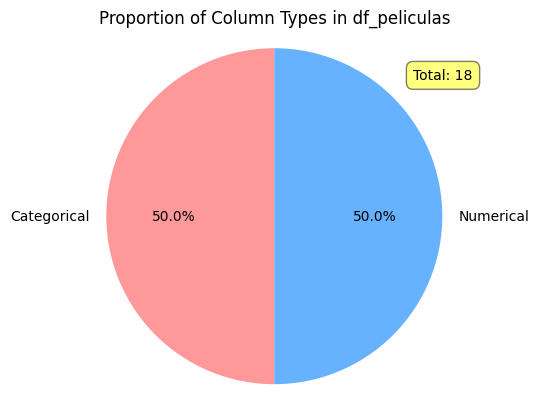


--- DataFrame: df_series ---
Columnas Numéricas: ['show_id', 'release_year', 'rating', 'popularity', 'vote_count', 'vote_average']
Columnas Categóricas: ['type', 'title', 'director', 'cast', 'country', 'date_added', 'duration', 'genres', 'language', 'description']


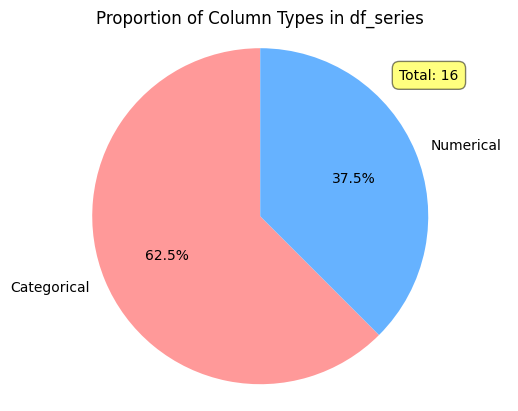

In [ ]:


def classify_columns(df, df_name):
    categorical_cols = []
    numerical_cols = []

    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            numerical_cols.append(col)
        else:
            categorical_cols.append(col)

    print(f"\n--- DataFrame: {df_name} ---")
    print(f"Columnas Numéricas: {numerical_cols}")
    print(f"Columnas Categóricas: {categorical_cols}")

    # Generate pie chart
    labels = ['Categorical', 'Numerical']
    sizes = [len(categorical_cols), len(numerical_cols)]
    total_columns = len(df.columns)

    fig1, ax1 = plt.subplots()
    wedges, texts, autotexts = ax1.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=['#FF9999', '#66B2FF'])
    ax1.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

    ax1.text(0.9, 0.9, f'Total: {total_columns}', transform=ax1.transAxes, fontsize=10, verticalalignment='top', horizontalalignment='right', bbox=dict(boxstyle='round,pad=0.5', fc='yellow', alpha=0.5))

    plt.title(f'Proportion of Column Types in {df_name}')
    plt.show()

# Classify and plot for df_peliculas
classify_columns(df_peliculas, 'df_peliculas')

# Classify and plot for df_series
classify_columns(df_series, 'df_series')


# Limpieza

In [ ]:
nulos = df_peliculas.isnull().sum()

# 2. Calcular el porcentaje que representan sobre el total de filas
porcentaje = (nulos / len(df_peliculas)) * 100

# 3. Crear la tabla de resumen
tabla_nulos = pd.DataFrame({
    'Cantidad de Nulos': nulos,
    'Porcentaje (%)': porcentaje.round(2)
})

# 4. Ordenar de mayor a menor cantidad de nulos
tabla_nulos = tabla_nulos.sort_values(by='Cantidad de Nulos', ascending=False)
tabla_nulos

,Cantidad de Nulos,Porcentaje (%)
duration,16000,100.00
country,466,2.91
cast,204,1.27
director,132,0.82
description,132,0.82
genres,107,0.67
type,0,0.00
show_id,0,0.00
title,0,0.00
date_added,0,0.00


La columna duracion en esto. es insignificante, porque no tiene datos, por ende hay que eliminarla

In [ ]:
df_peliculas = df_peliculas.drop('duration', axis=1)

In [ ]:
nulos = df_series.isnull().sum()

# 2. Calcular el porcentaje que representan sobre el total de filas
porcentaje = (nulos / len(df_series)) * 100

# 3. Crear la tabla de resumen
tabla_nulos = pd.DataFrame({
    'Cantidad de Nulos': nulos,
    'Porcentaje (%)': porcentaje.round(2)
})

# 4. Ordenar de mayor a menor cantidad de nulos
tabla_nulos = tabla_nulos.sort_values(by='Cantidad de Nulos', ascending=False)
tabla_nulos

,Cantidad de Nulos,Porcentaje (%)
director,10965,68.53
description,3206,20.04
country,1797,11.23
cast,1157,7.23
genres,974,6.09
type,0,0.00
title,0,0.00
show_id,0,0.00
release_year,0,0.00
date_added,0,0.00


Hay muy poca informacion  con las columnas categoricas, por ende se llenaran con "Unkwon"

In [ ]:


def fill_categorical_nan_with_unknown(df, df_name):
    categorical_cols = [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])]
    print(f"Processing NaN values in categorical columns for {df_name}...")
    for col in categorical_cols:
        df[col] = df[col].fillna("Unknown")
    print(f"NaN values in categorical columns of {df_name} have been replaced with 'Unknown'.")
    return df

# Process df_peliculas
df_peliculas = fill_categorical_nan_with_unknown(df_peliculas, 'df_peliculas')

# Process df_series
df_series = fill_categorical_nan_with_unknown(df_series, 'df_series')

print("\nFirst 5 rows of df_peliculas after NaN treatment:")
print(df_peliculas.head())
print("\nFirst 5 rows of df_series after NaN treatment:")
print(df_series.head())


Processing NaN values in categorical columns for df_peliculas...
NaN values in categorical columns of df_peliculas have been replaced with 'Unknown'.
Processing NaN values in categorical columns for df_series...
NaN values in categorical columns of df_series have been replaced with 'Unknown'.

First 5 rows of df_peliculas after NaN treatment:
   show_id   type                                         title  \
0    10192  Movie                           Shrek Forever After   
1    27205  Movie                                     Inception   
2    12444  Movie  Harry Potter and the Deathly Hallows: Part 1   
3    38757  Movie                                       Tangled   
4    10191  Movie                      How to Train Your Dragon   

                      director  \
0                Mike Mitchell   
1            Christopher Nolan   
2                  David Yates   
3   Byron Howard, Nathan Greno   
4  Chris Sanders, Dean DeBlois   

                                               

In [ ]:
print("\n--- Imputing numerical NaN values using KNN for df_peliculas ---")
# Identify numerical columns with missing values in df_peliculas
numerical_cols_peliculas = df_peliculas.select_dtypes(include=np.number).columns
missing_numerical_cols_peliculas = [col for col in numerical_cols_peliculas if df_peliculas[col].isnull().any()]

if missing_numerical_cols_peliculas:
    imputer_peliculas = KNNImputer(n_neighbors=5) # You can adjust n_neighbors as needed
    # Impute and explicitly convert the numpy array output back to a DataFrame for correct assignment
    imputed_data_peliculas = imputer_peliculas.fit_transform(df_peliculas[missing_numerical_cols_peliculas])

    # Check if the imputer returned any columns before attempting assignment
    if imputed_data_peliculas.shape[1] > 0:
        df_peliculas[missing_numerical_cols_peliculas] = pd.DataFrame(imputed_data_peliculas, columns=missing_numerical_cols_peliculas, index=df_peliculas.index)
        print("Numerical NaN values in df_peliculas imputed successfully.")
    else:
        print(f"Warning: KNNImputer returned no columns for df_peliculas, even though {len(missing_numerical_cols_peliculas)} were expected. Skipping imputation for these columns.")
        print("Consider checking the 'duration' column for non-numeric data or if it's entirely NaN.")
else:
    print("No missing numerical values found in df_peliculas.")

print("\n--- Imputing numerical NaN values using KNN for df_series ---")
# Identify numerical columns with missing values in df_series
numerical_cols_series = df_series.select_dtypes(include=np.number).columns
missing_numerical_cols_series = [col for col in numerical_cols_series if df_series[col].isnull().any()]

if missing_numerical_cols_series:
    imputer_series = KNNImputer(n_neighbors=5) # You can adjust n_neighbors as needed
    # Impute and explicitly convert the numpy array output back to a DataFrame for correct assignment
    imputed_data_series = imputer_series.fit_transform(df_series[missing_numerical_cols_series])

    # Check if the imputer returned any columns before attempting assignment
    if imputed_data_series.shape[1] > 0:
        df_series[missing_numerical_cols_series] = pd.DataFrame(imputed_data_series, columns=missing_numerical_cols_series, index=df_series.index)
        print("Numerical NaN values in df_series imputed successfully.")
    else:
        print(f"Warning: KNNImputer returned no columns for df_series, even though {len(missing_numerical_cols_series)} were expected. Skipping imputation for these columns.")
else:
    print("No missing numerical values found in df_series.")

print("\nFirst 5 rows of df_peliculas after numerical NaN treatment:")
display(df_peliculas.head())
print("\nFirst 5 rows of df_series after numerical NaN treatment:")
display(df_series.head())


--- Imputing numerical NaN values using KNN for df_peliculas ---
No missing numerical values found in df_peliculas.

--- Imputing numerical NaN values using KNN for df_series ---
No missing numerical values found in df_series.

First 5 rows of df_peliculas after numerical NaN treatment:


,show_id,type,title,director,cast,country,date_added,release_year,rating,genres,language,description,popularity,vote_count,vote_average,budget,revenue
0,10192,Movie,Shrek Forever After,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antoni...",United States of America,2010-05-16,2010,6.380,"Comedy, Adventure, Fantasy, Animation, Family",en,A bored and domesticated Shrek pacts with deal...,203.893,7449,6.380,165000000,752600867
1,27205,Movie,Inception,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ken W...","United Kingdom, United States of America",2010-07-15,2010,8.369,"Action, Science Fiction, Adventure",en,"Cobb, a skilled thief who commits corporate es...",156.242,37119,8.369,160000000,839030630
2,12444,Movie,Harry Potter and the Deathly Hallows: Part 1,David Yates,"Daniel Radcliffe, Emma Watson, Rupert Grint, T...","United Kingdom, United States of America",2010-11-17,2010,7.744,"Adventure, Fantasy",en,"Harry, Ron and Hermione walk away from their l...",121.191,19327,7.744,250000000,954305868
3,38757,Movie,Tangled,"Byron Howard, Nathan Greno","Mandy Moore, Zachary Levi, Donna Murphy, Ron P...",United States of America,2010-11-24,2010,7.600,"Animation, Family, Adventure",en,"Feisty teenager Rapunzel, who has long and mag...",111.762,11638,7.600,260000000,592461732
4,10191,Movie,How to Train Your Dragon,"Chris Sanders, Dean DeBlois","Jay Baruchel, Gerard Butler, Craig Ferguson, A...",United States of America,2010-03-18,2010,7.800,"Fantasy, Adventure, Animation, Family",en,As the son of a Viking leader on the cusp of m...,110.044,13259,7.800,165000000,494879471



First 5 rows of df_series after numerical NaN treatment:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,language,description,popularity,vote_count,vote_average
0,33238,TV Show,Running Man,안재철,"Yoo Jae-suk, Jee Seok-jin, Kim Jong-kook, Haha...",South Korea,2010-07-11,2010,8.241,1 Seasons,"Comedy, Reality",ko,A reality and competition show where members a...,1929.898,187,8.241
1,32415,TV Show,Conan,Unknown,"Conan O'Brien, Andy Richter",United States of America,2010-11-08,2010,7.035,1 Seasons,"Talk, Comedy, News",en,A late night television talk show hosted by C...,1670.580,229,7.035
2,37757,TV Show,MasterChef Greece,Unknown,Unknown,Greece,2010-10-03,2010,5.600,1 Seasons,Reality,el,MasterChef Greece is a Greek competitive cooki...,1317.092,6,5.600
3,75685,TV Show,Prostřeno!,Unknown,"Václav Vydra, Jana Boušková",Czech Republic,2010-03-01,2010,6.500,1 Seasons,Reality,cs,The knives (and forks) are out as a group of s...,1095.776,6,6.500
4,33847,TV Show,The Talk,Unknown,"Amanda Kloots, Jerry O'Connell, Akbar Gbaja-Bi...","United States of America, Ireland",2010-10-18,2010,3.400,1 Seasons,Talk,en,A panel of well-known news and entertainment p...,712.070,12,3.400


In [ ]:
nulos = df_peliculas.isnull().sum()

# 2. Calcular el porcentaje que representan sobre el total de filas
porcentaje = (nulos / len(df_peliculas)) * 100

# 3. Crear la tabla de resumen
tabla_nulos = pd.DataFrame({
    'Cantidad de Nulos': nulos,
    'Porcentaje (%)': porcentaje.round(2)
})

# 4. Ordenar de mayor a menor cantidad de nulos
tabla_nulos = tabla_nulos.sort_values(by='Cantidad de Nulos', ascending=False)
tabla_nulos

,Cantidad de Nulos,Porcentaje (%)
show_id,0,0.0
type,0,0.0
title,0,0.0
director,0,0.0
cast,0,0.0
country,0,0.0
date_added,0,0.0
release_year,0,0.0
rating,0,0.0
genres,0,0.0


In [ ]:
nulos = df_series.isnull().sum()

# 2. Calcular el porcentaje que representan sobre el total de filas
porcentaje = (nulos / len(df_series)) * 100

# 3. Crear la tabla de resumen
tabla_nulos = pd.DataFrame({
    'Cantidad de Nulos': nulos,
    'Porcentaje (%)': porcentaje.round(2)
})

# 4. Ordenar de mayor a menor cantidad de nulos
tabla_nulos = tabla_nulos.sort_values(by='Cantidad de Nulos', ascending=False)
tabla_nulos

,Cantidad de Nulos,Porcentaje (%)
show_id,0,0.0
type,0,0.0
title,0,0.0
director,0,0.0
cast,0,0.0
country,0,0.0
date_added,0,0.0
release_year,0,0.0
rating,0,0.0
duration,0,0.0


#Relaciones


In [ ]:
conteo_por_anio_series  = df_series.groupby('release_year').size().reset_index(name='cantidad_series')

conteo_por_anio_series

,release_year,cantidad_series
0,2010,1000
1,2011,1000
2,2012,1000
3,2013,1000
4,2014,1000
5,2015,1000
6,2016,1000
7,2017,1000
8,2018,1000
9,2019,1000


In [ ]:
conteo_por_anio_pelis = df_peliculas.groupby('release_year').size().reset_index(name='cantidad_series')

conteo_por_anio_pelis

,release_year,cantidad_series
0,2010,1000
1,2011,1000
2,2012,1000
3,2013,1000
4,2014,1000
5,2015,1000
6,2016,1000
7,2017,1000
8,2018,1000
9,2019,1000


Podemos observar que tenemos un rango temporal de 15 años desde el 2010 al 2025, que nos da mil peliculas y series por año, lo cual es bueno, ya que son datos frescos que responden a las tendencias contemporaneas

#Analisis de popularidad

In [ ]:
def top_por_popularidad(df, columna_objetivo, min_apariciones=10, top_n=10):
    # 1. Crear el DataFrame temporal y eliminar nulos
    df_temp = df[[columna_objetivo, 'popularity']].dropna(subset=[columna_objetivo]).copy()

    # 2. Excluir filas donde el valor exacto sea 'Unknown'
    df_temp = df_temp[df_temp[columna_objetivo].str.strip().str.lower() != 'unknown']

    # 3. Filtrar outliers de popularidad usando el Rango Intercuartílico (IQR)
    Q1 = df_temp['popularity'].quantile(0.25)
    Q3 = df_temp['popularity'].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    df_temp = df_temp[(df_temp['popularity'] >= limite_inferior) & (df_temp['popularity'] <= limite_superior)]

    # 4. Separar los nombres por coma para convertirlos en una lista
    df_temp[columna_objetivo] = df_temp[columna_objetivo].str.split(',')

    # 5. Explotar la lista
    df_exploded = df_temp.explode(columna_objetivo)

    # 6. Limpiar los espacios en blanco
    df_exploded[columna_objetivo] = df_exploded[columna_objetivo].str.strip()

    # 7. Segundo filtro de 'Unknown' por si venía combinado
    df_exploded = df_exploded[df_exploded[columna_objetivo].str.lower() != 'unknown']

    # 8. Agrupar y calcular la MEDIA
    agrupado = df_exploded.groupby(columna_objetivo).agg(
        media_popularidad=('popularity', 'mean'),
        cantidad_series=('popularity', 'count')
    )

    # 9. Filtrar por un mínimo de apariciones
    agrupado = agrupado[agrupado['cantidad_series'] >= min_apariciones]

    # 10. Ordenar de mayor a menor
    top_final = agrupado.sort_values(by='media_popularidad', ascending=False).head(top_n)

    return top_final

# Ejecución con umbrales altos para asegurar consistencia
top_actores_series = top_por_popularidad(df_series, columna_objetivo='cast', min_apariciones=5)
top_directores_series = top_por_popularidad(df_series, columna_objetivo='director', min_apariciones=5)

top_actores_pelis = top_por_popularidad(df_peliculas, columna_objetivo='cast', min_apariciones=5)
top_directores_pelis = top_por_popularidad(df_peliculas, columna_objetivo='director', min_apariciones=5)

/tmp/ipykernel_3449/3414477966.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_3449/3414477966.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_3449/3414477966.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_3449/3414477966.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


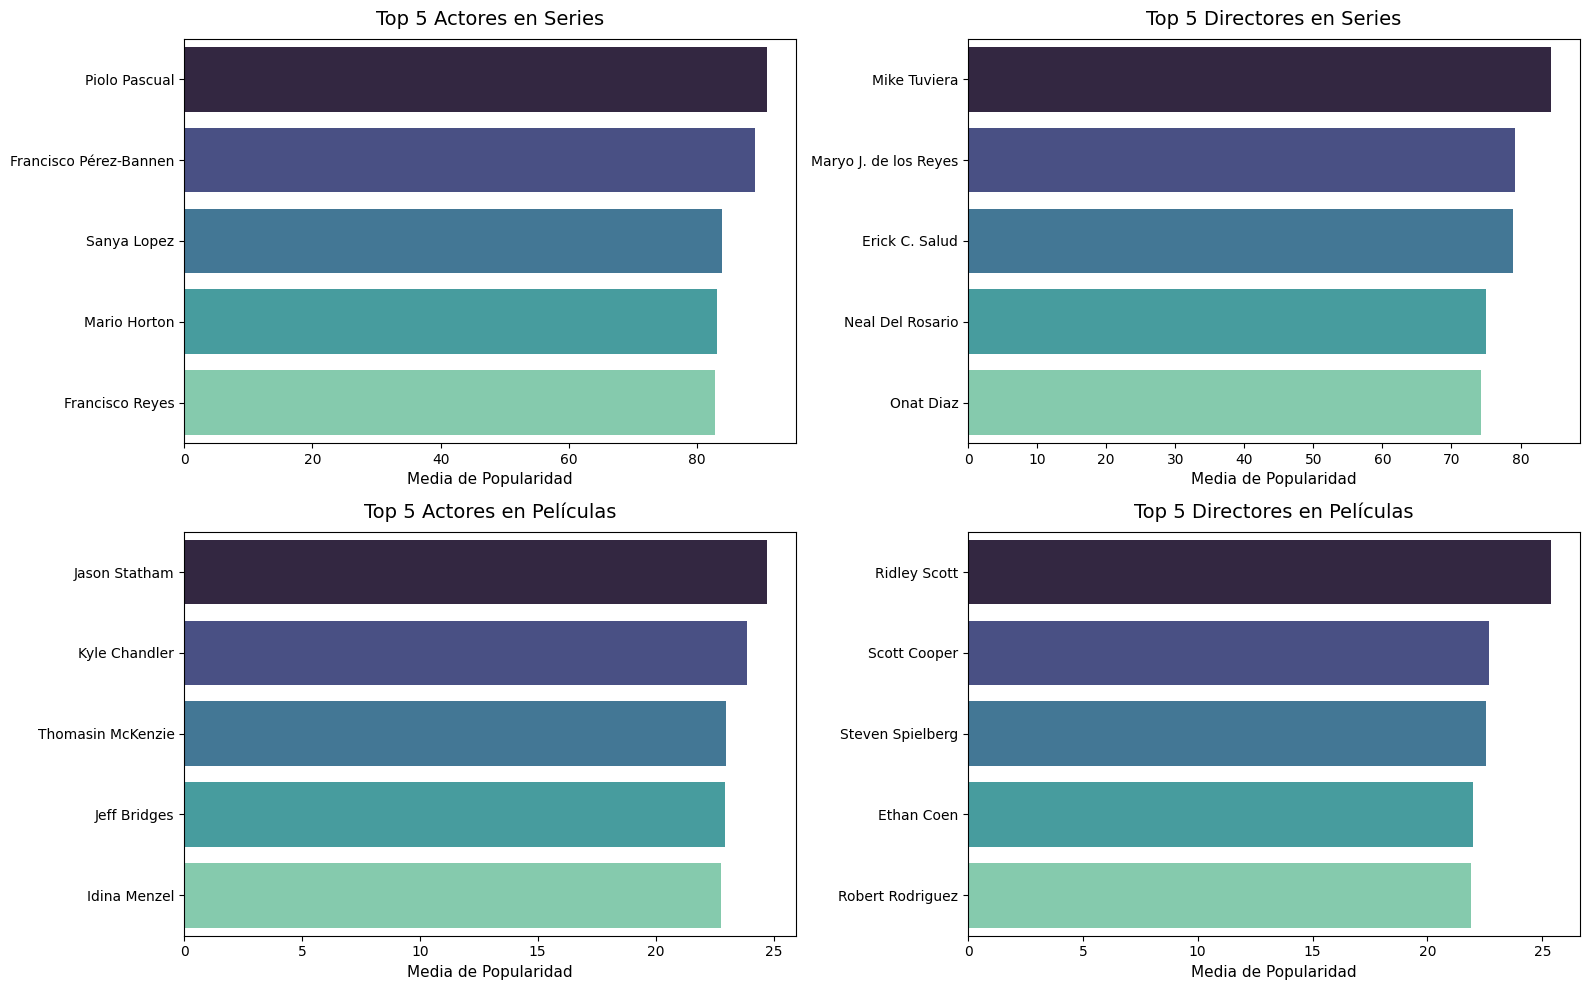

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

data_plots = [
    (top_actores_series.head(5), 'Top 5 Actores en Series', 'cast', axes[0, 0]),
    (top_directores_series.head(5), 'Top 5 Directores en Series', 'director', axes[0, 1]),
    (top_actores_pelis.head(5), 'Top 5 Actores en Películas', 'cast', axes[1, 0]),
    (top_directores_pelis.head(5), 'Top 5 Directores en Películas', 'director', axes[1, 1])
]

for df_top, titulo, col_nombre, ax in data_plots:
    df_plot = df_top.reset_index()

    sns.barplot(
        data=df_plot,
        x='media_popularidad',
        y=col_nombre,
        ax=ax,
        palette='mako'
    )

    ax.set_title(titulo, fontsize=14, pad=10)
    ax.set_xlabel('Media de Popularidad', fontsize=11)
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

Notamos que deberiamos dividirlos por lenguaje para obtener una mirada más objetiva

In [ ]:

def top_idiomas_cantidad(df, columna_lenguaje='language', top_n=5):
    # 1. Crear DataFrame temporal y eliminar nulos
    df_temp = df[[columna_lenguaje]].dropna().copy()

    # 2. Excluir la etiqueta 'Unknown'
    df_temp = df_temp[df_temp[columna_lenguaje].str.strip().str.lower() != 'unknown']

    # 3. Separar por comas y explotar (útil si un título tiene múltiples idiomas listados)
    df_temp[columna_lenguaje] = df_temp[columna_lenguaje].str.split(',')
    df_exploded = df_temp.explode(columna_lenguaje)

    # 4. Limpiar espacios en blanco
    df_exploded[columna_lenguaje] = df_exploded[columna_lenguaje].str.strip()

    # 5. Contar la cantidad total de apariciones por idioma
    conteo_idiomas = df_exploded[columna_lenguaje].value_counts().reset_index()
    conteo_idiomas.columns = [columna_lenguaje, 'cantidad_titulos']

    # 6. Retornar el top N
    return conteo_idiomas.head(top_n)

# --- CÁLCULO DE LOS DATOS ---
# Recuerda cambiar 'language' por el nombre real de tu columna si es diferente
top_lang_series = top_idiomas_cantidad(df_series, columna_lenguaje='language', top_n=5)
top_lang_pelis = top_idiomas_cantidad(df_peliculas, columna_lenguaje='language', top_n=5)

/tmp/ipykernel_3449/239968237.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_3449/239968237.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


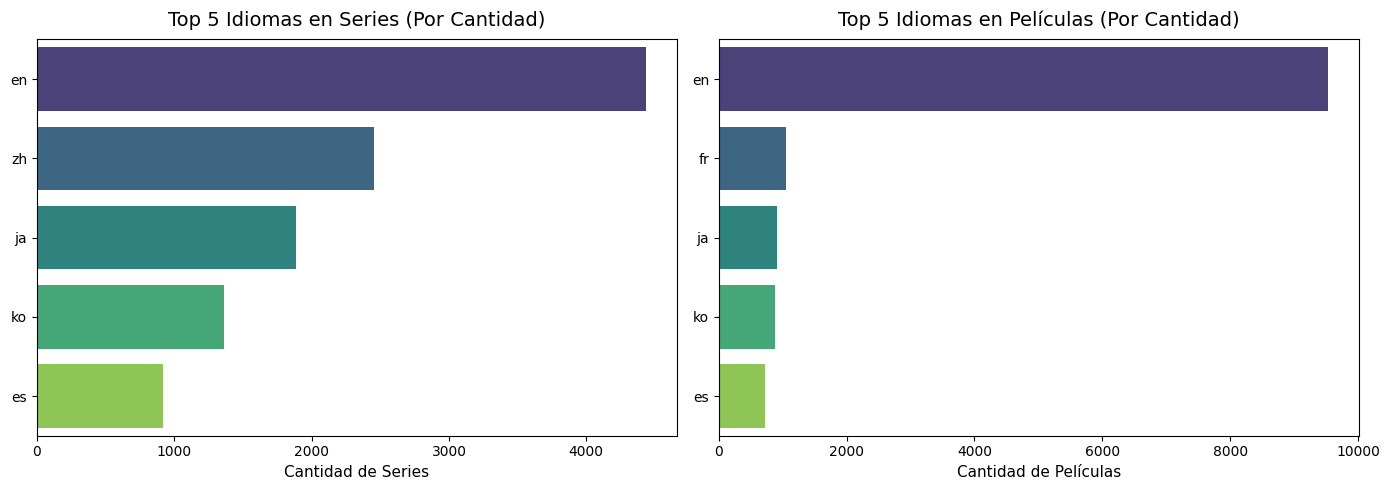

In [ ]:
# --- BLOQUE DE VISUALIZACIÓN ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Series
sns.barplot(
    data=top_lang_series,
    x='cantidad_titulos',
    y='language',
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Top 5 Idiomas en Series (Por Cantidad)', fontsize=14, pad=10)
axes[0].set_xlabel('Cantidad de Series', fontsize=11)
axes[0].set_ylabel('')

# Gráfico 2: Películas
sns.barplot(
    data=top_lang_pelis,
    x='cantidad_titulos',
    y='language',
    ax=axes[1],
    palette='viridis'
)
axes[1].set_title('Top 5 Idiomas en Películas (Por Cantidad)', fontsize=14, pad=10)
axes[1].set_xlabel('Cantidad de Películas', fontsize=11)
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

Logramos obtener una gran cantidad devolumen en las peliculas en ingles y chino, en las series,
en las peliculas hay un valor predominante en el idioma ingles.

AHora veremos a los actores y directores más famosos en los idiomas top

In [ ]:
def top_por_popularidad_por_idioma(df, columna_objetivo, columna_idioma=None, idiomas_permitidos=None, min_apariciones=10, top_n=10):
    # 1. Definir columnas a extraer
    columnas = [columna_objetivo, 'popularity', 'title']
    if columna_idioma:
        columnas.append(columna_idioma)

    # 2. Crear el DataFrame temporal y eliminar nulos
    df_temp = df[columnas].dropna(subset=[columna_objetivo, 'title']).copy()

    # 3. Limpiar los espacios de los títulos para evitar que "Serie A" y " Serie A" cuenten como dos distintas
    df_temp['title'] = df_temp['title'].str.strip()

    # 4. Aplicar filtro de idioma
    if columna_idioma and idiomas_permitidos:
        idiomas_limpios = [idioma.lower().strip() for idioma in idiomas_permitidos]
        patron_regex = '|'.join([rf"\b{idioma}\b" for idioma in idiomas_limpios])
        df_temp = df_temp[df_temp[columna_idioma].str.strip().str.lower().str.contains(patron_regex, regex=True, na=False)]

    # 5. Excluir filas donde el valor exacto sea 'Unknown'
    df_temp = df_temp[df_temp[columna_objetivo].str.strip().str.lower() != 'unknown']

    # 6. Separar los nombres por coma para convertirlos en una lista y explotar
    df_temp[columna_objetivo] = df_temp[columna_objetivo].str.split(',')
    df_exploded = df_temp.explode(columna_objetivo)

    # 7. Limpiar los espacios en blanco de los nombres
    df_exploded[columna_objetivo] = df_exploded[columna_objetivo].str.strip()

    # 8. Segundo filtro de 'Unknown' post-separación
    df_exploded = df_exploded[df_exploded[columna_objetivo].str.lower() != 'unknown']

    # 9. CORRECCIÓN DEFINITIVA: Eliminar duplicados exactos por Persona y Título
    # Esto asegura que la mediana y el conteo sean matemáticamente perfectos
    df_exploded = df_exploded.drop_duplicates(subset=[columna_objetivo, 'title'])

    # 10. Agrupar y calcular MEDIANA y CONTEO
    agrupado = df_exploded.groupby(columna_objetivo).agg(
        mediana_popularidad=('popularity', 'median'),
        cantidad_series=('title', 'count')
    )

    # 11. Filtrar por el mínimo real de producciones
    agrupado = agrupado[agrupado['cantidad_series'] >= min_apariciones]

    # 12. Ordenar de mayor a menor según la mediana
    top_final = agrupado.sort_values(by='mediana_popularidad', ascending=False).head(top_n)

    return top_final

# --- EJECUCIÓN ---
idiomas_series = ['zh', 'ja', 'en']
top_actores_series = top_por_popularidad_por_idioma(
    df_series, 'cast', columna_idioma='language', idiomas_permitidos=idiomas_series, min_apariciones=8
)
top_directores_series = top_por_popularidad_por_idioma(
    df_series, 'director', columna_idioma='language', idiomas_permitidos=idiomas_series, min_apariciones=8
)

idiomas_pelis = ['en']
top_actores_pelis = top_por_popularidad_por_idioma(
    df_peliculas, 'cast', columna_idioma='language', idiomas_permitidos=idiomas_pelis, min_apariciones=8
)
top_directores_pelis = top_por_popularidad_por_idioma(
    df_peliculas, 'director', columna_idioma='language', idiomas_permitidos=idiomas_pelis, min_apariciones=8
)

/tmp/ipykernel_3449/3481500373.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_3449/3481500373.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_3449/3481500373.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_3449/3481500373.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


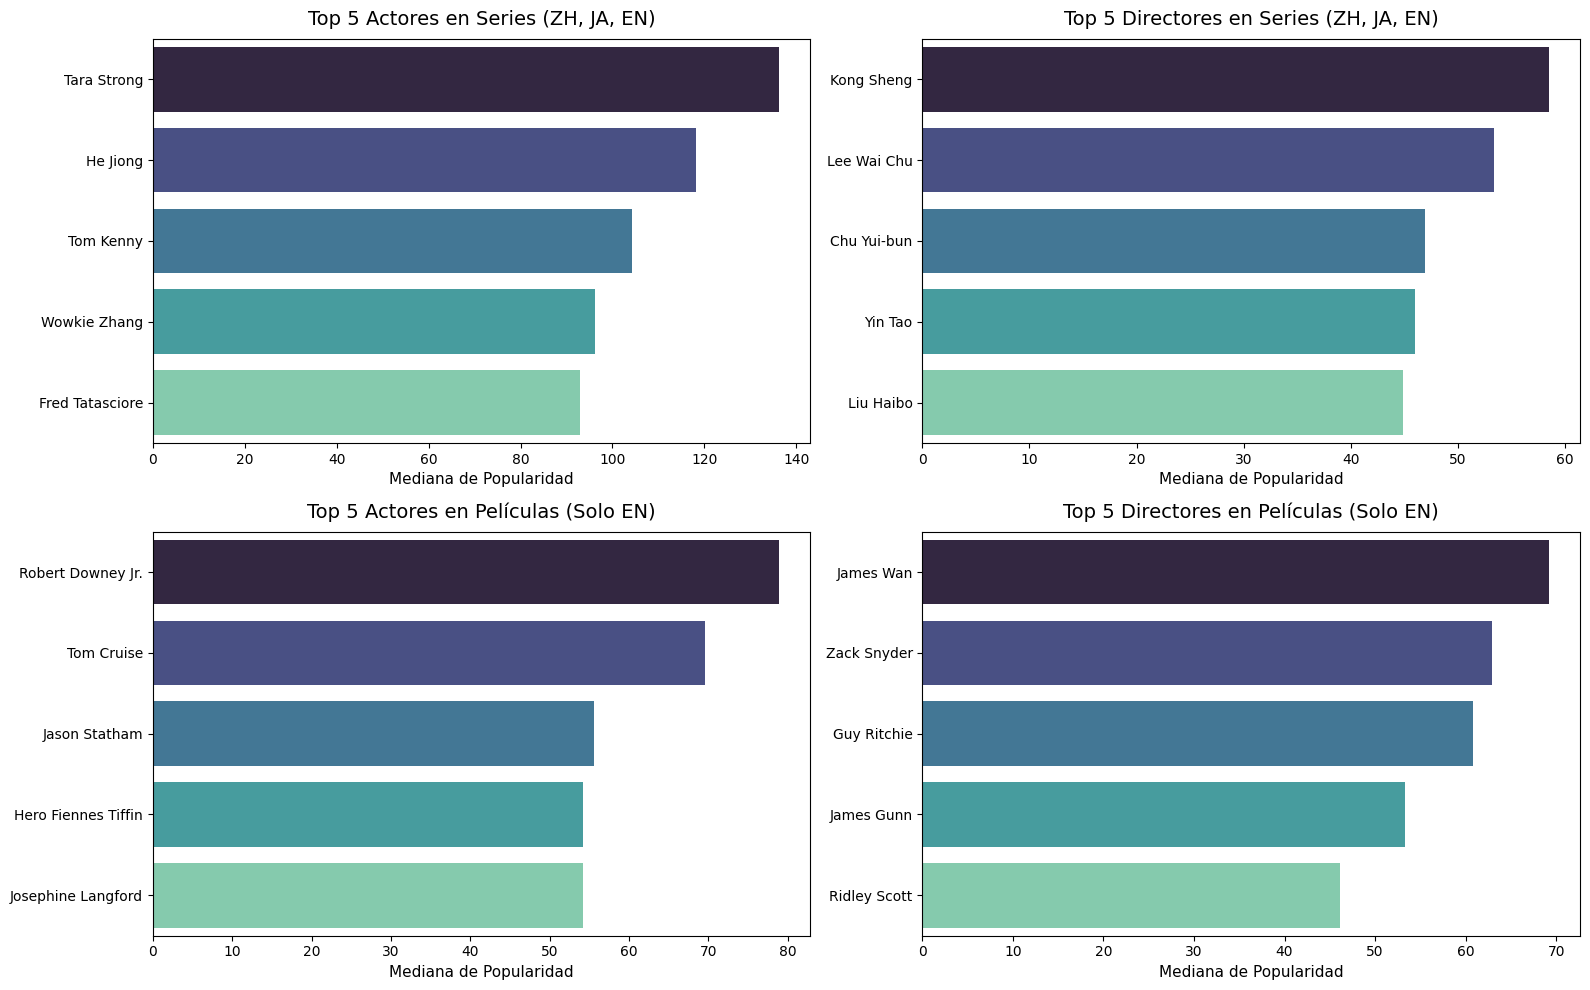

In [ ]:

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

data_plots = [
    (top_actores_series.head(5), 'Top 5 Actores en Series (ZH, JA, EN)', 'cast', axes[0, 0]),
    (top_directores_series.head(5), 'Top 5 Directores en Series (ZH, JA, EN)', 'director', axes[0, 1]),
    (top_actores_pelis.head(5), 'Top 5 Actores en Películas (Solo EN)', 'cast', axes[1, 0]),
    (top_directores_pelis.head(5), 'Top 5 Directores en Películas (Solo EN)', 'director', axes[1, 1])
]

for df_top, titulo, col_nombre, ax in data_plots:
    # Reiniciar el índice para que el nombre vuelva a ser una columna normal
    df_plot = df_top.reset_index()

    # Crear el gráfico de barras horizontal (ACTUALIZADO a mediana)
    sns.barplot(
        data=df_plot,
        x='mediana_popularidad',
        y=col_nombre,
        ax=ax,
        palette='mako'
    )

    # Configurar títulos y etiquetas para cada subgráfico
    ax.set_title(titulo, fontsize=14, pad=10)
    ax.set_xlabel('Mediana de Popularidad', fontsize=11) # ACTUALIZADO
    ax.set_ylabel('')

# Ajustar los espacios entre los gráficos
plt.tight_layout()
plt.show()

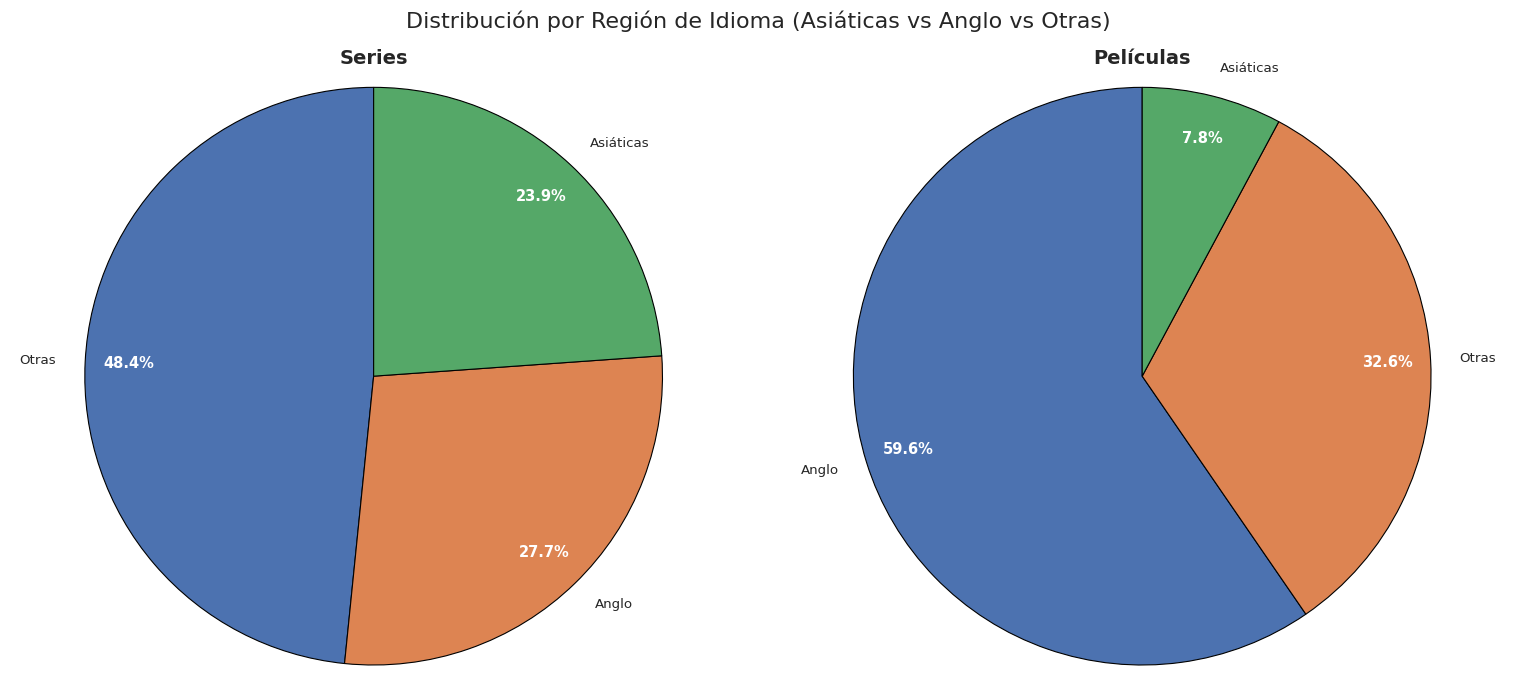

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Definición de idiomas por grupo
asian_langs = ['zh', 'jp', 'ko']
us_langs = ['en']

# Función para verificar la presencia de un idioma
def check_language_presence(language_string, target_languages):
    if pd.isna(language_string) or language_string == 'Unknown':
        return False
    languages_in_cell = [lang.strip().lower() for lang in language_string.split(',')]
    for target_lang in target_languages:
        if target_lang.lower() in languages_in_cell:
            return True
    return False

# Función para clasificar cada dataset en Asiáticas, Estadounidenses u Otras
def classify_language_group(df, lang_column='language'):
    df_copy = df.copy()
    df_copy['language_group'] = 'Otras'

    # Clasificar como Asiáticas primero (prioridad)
    is_asian = df_copy[lang_column].apply(lambda x: check_language_presence(x, asian_langs))
    df_copy.loc[is_asian, 'language_group'] = 'Asiáticas'

    # Clasificar como Estadounidenses sólo si no es Asiática
    is_us = df_copy[lang_column].apply(lambda x: check_language_presence(x, us_langs))
    df_copy.loc[(df_copy['language_group'] == 'Otras') & is_us, 'language_group'] = 'Anglo'

    return df_copy

# Clasificar ambos DataFrames independientemente
df_series_classified = classify_language_group(df_series, lang_column='language')
df_peliculas_classified = classify_language_group(df_peliculas, lang_column='language')

# Conteo de categorías
series_counts = df_series_classified['language_group'].value_counts()
peliculas_counts = df_peliculas_classified['language_group'].value_counts()

# Crear figura con 2 subgráficos (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Gráfico 1: Series
wedges1, texts1, autotexts1 = ax1.pie(
    series_counts.values,
    labels=series_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.85,
    wedgeprops={'edgecolor': 'black'}
)
ax1.set_title('Series', fontsize=14, fontweight='bold')
ax1.axis('equal')

for autotext in autotexts1:
    autotext.set_color('white')
    autotext.set_weight('bold')

# Gráfico 2: Películas
wedges2, texts2, autotexts2 = ax2.pie(
    peliculas_counts.values,
    labels=peliculas_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.85,
    wedgeprops={'edgecolor': 'black'}
)
ax2.set_title('Películas', fontsize=14, fontweight='bold')
ax2.axis('equal')

for autotext in autotexts2:
    autotext.set_color('white')
    autotext.set_weight('bold')

plt.suptitle('Distribución por Región de Idioma (Asiáticas vs Anglo vs Otras)', fontsize=16)
plt.tight_layout()
plt.show()

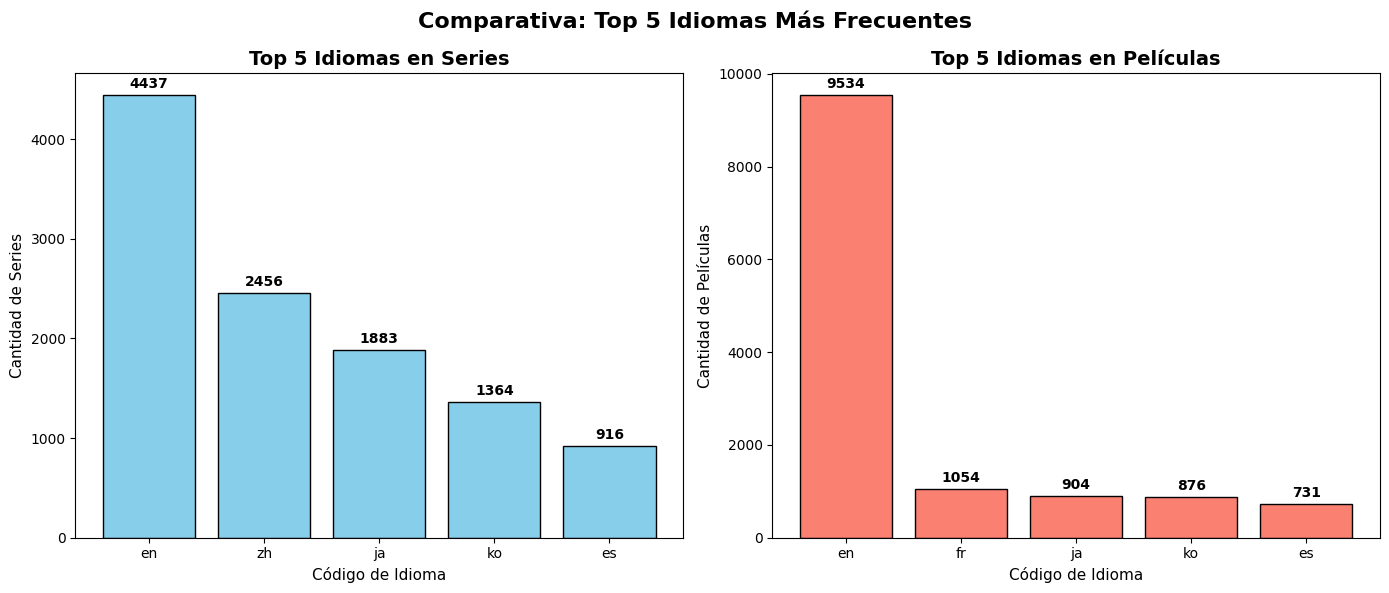

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


def get_top_languages(df, lang_column="language", top_n=5):
    # Filtrar valores nulos o 'Unknown'
    valid_langs = df[lang_column].dropna()
    valid_langs = valid_langs[valid_langs != "Unknown"]

    # Separar idiomas en celdas con comas, limpiar espacios y convertir a minúsculas
    exploded = (
        valid_langs.astype(str)
        .str.split(",")
        .explode()
        .str.strip()
        .str.lower()
    )

    # Retornar los N idiomas más frecuentes
    return exploded[exploded != ""].value_counts().head(top_n)


# Obtener Top 5 para cada grupo
top5_series = get_top_languages(df_series)
top5_peliculas = get_top_languages(df_peliculas)

# Crear figura con 2 subgráficos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Gráfico 1: Top 5 Series
bars1 = ax1.bar(
    top5_series.index, top5_series.values, color="skyblue", edgecolor="black"
)
ax1.set_title("Top 5 Idiomas en Series", fontsize=14, fontweight="bold")
ax1.set_xlabel("Código de Idioma", fontsize=11)
ax1.set_ylabel("Cantidad de Series", fontsize=11)
ax1.bar_label(bars1, padding=3, fontweight="bold")  # Muestra el valor sobre cada barra

# Gráfico 2: Top 5 Películas
bars2 = ax2.bar(
    top5_peliculas.index,
    top5_peliculas.values,
    color="salmon",
    edgecolor="black",
)
ax2.set_title("Top 5 Idiomas en Películas", fontsize=14, fontweight="bold")
ax2.set_xlabel("Código de Idioma", fontsize=11)
ax2.set_ylabel("Cantidad de Películas", fontsize=11)
ax2.bar_label(bars2, padding=3, fontweight="bold")

plt.suptitle(
    "Comparativa: Top 5 Idiomas Más Frecuentes", fontsize=16, fontweight="bold"
)
plt.tight_layout()
plt.show()

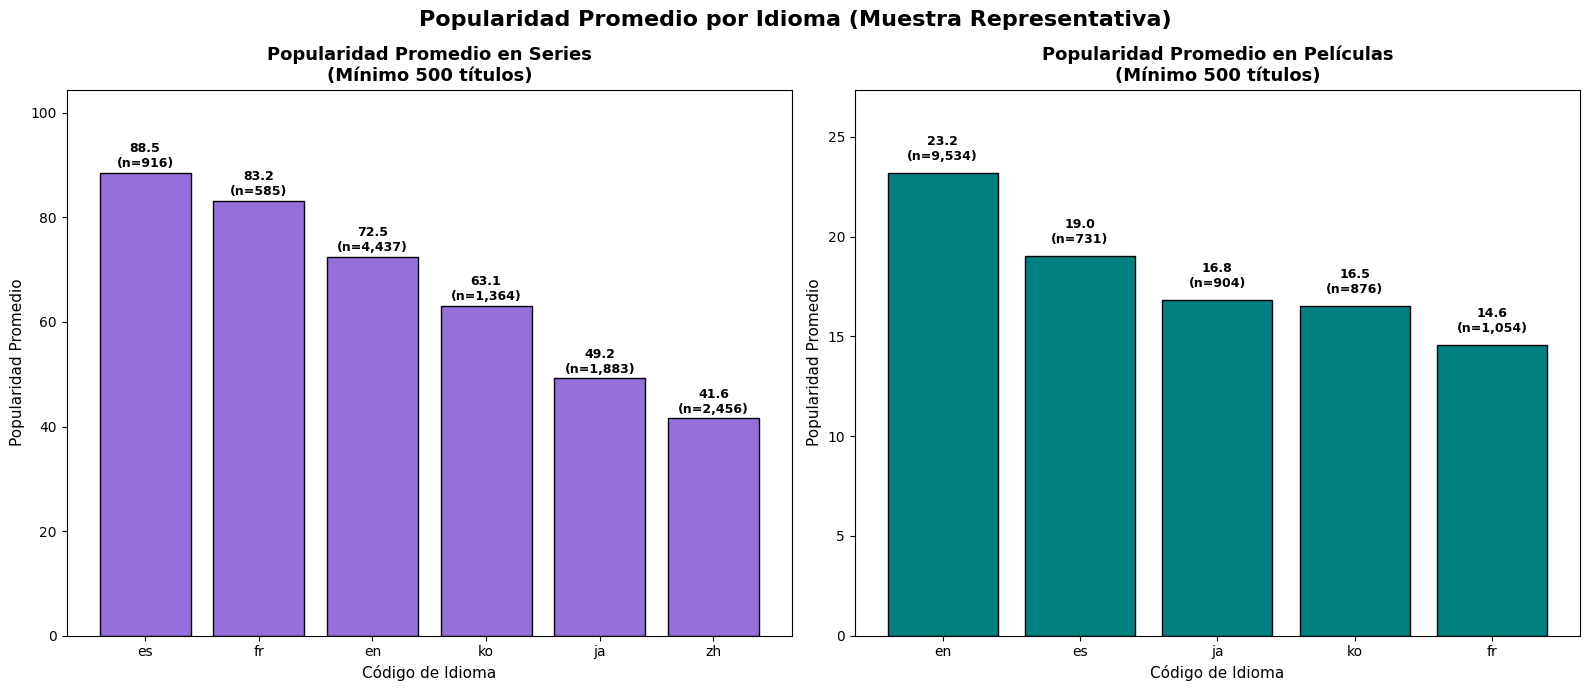

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


def get_representative_avg_popularity(
    df,
    lang_column="language",
    pop_column="popularity",
    min_titles=1000,
    top_n=10,
):
    valid_df = df[[lang_column, pop_column]].dropna()
    valid_df = valid_df[valid_df[lang_column] != "Unknown"]

    # Descomponer idiomas separados por comas
    exploded_rows = []
    for _, row in valid_df.iterrows():
        langs = [
            l.strip().lower()
            for l in str(row[lang_column]).split(",")
            if l.strip()
        ]
        for lang in langs:
            exploded_rows.append(
                {lang_column: lang, pop_column: row[pop_column]}
            )

    exploded_df = pd.DataFrame(exploded_rows)

    # Calcular promedio y tamaño de muestra por idioma
    grouped = exploded_df.groupby(lang_column)[pop_column].agg(
        ["mean", "count"]
    )

    # Filtro con el nuevo umbral para datasets grandes (N >= 1,000)
    filtered = grouped[grouped["count"] >= min_titles]

    return filtered.sort_values(by="mean", ascending=False).head(top_n)


# Umbral adaptado a datasets masivos
MIN_TITULOS = 500
pop_column_name = "popularity"  # Ajustar si el nombre de columna varía

avg_series = get_representative_avg_popularity(
    df_series,
    lang_column="language",
    pop_column=pop_column_name,
    min_titles=MIN_TITULOS,
    top_n=10,
)

avg_peliculas = get_representative_avg_popularity(
    df_peliculas,
    lang_column="language",
    pop_column=pop_column_name,
    min_titles=MIN_TITULOS,
    top_n=10,
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Gráfico 1: Series
if not avg_series.empty:
    bars1 = ax1.bar(
        avg_series.index,
        avg_series["mean"],
        color="mediumpurple",
        edgecolor="black",
    )
    ax1.set_title(
        f"Popularidad Promedio en Series\n(Mínimo {MIN_TITULOS:,} títulos)",
        fontsize=13,
        fontweight="bold",
    )
    ax1.set_xlabel("Código de Idioma", fontsize=11)
    ax1.set_ylabel("Popularidad Promedio", fontsize=11)
    ax1.set_ylim(0, avg_series["mean"].max() * 1.18)

    for bar, mean_val, count_val in zip(
        bars1, avg_series["mean"], avg_series["count"]
    ):
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{mean_val:.1f}\n(n={count_val:,})",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )
else:
    ax1.text(
        0.5,
        0.5,
        f"Sin idiomas con al menos {MIN_TITULOS:,} series",
        ha="center",
        va="center",
        fontsize=12,
    )

# Gráfico 2: Películas
if not avg_peliculas.empty:
    bars2 = ax2.bar(
        avg_peliculas.index,
        avg_peliculas["mean"],
        color="teal",
        edgecolor="black",
    )
    ax2.set_title(
        f"Popularidad Promedio en Películas\n(Mínimo {MIN_TITULOS:,} títulos)",
        fontsize=13,
        fontweight="bold",
    )
    ax2.set_xlabel("Código de Idioma", fontsize=11)
    ax2.set_ylabel("Popularidad Promedio", fontsize=11)
    ax2.set_ylim(0, avg_peliculas["mean"].max() * 1.18)

    for bar, mean_val, count_val in zip(
        bars2, avg_peliculas["mean"], avg_peliculas["count"]
    ):
        ax2.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            f"{mean_val:.1f}\n(n={count_val:,})",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )
else:
    ax2.text(
        0.5,
        0.5,
        f"Sin idiomas con al menos {MIN_TITULOS:,} películas",
        ha="center",
        va="center",
        fontsize=12,
    )

plt.suptitle(
    "Popularidad Promedio por Idioma (Muestra Representativa)",
    fontsize=16,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

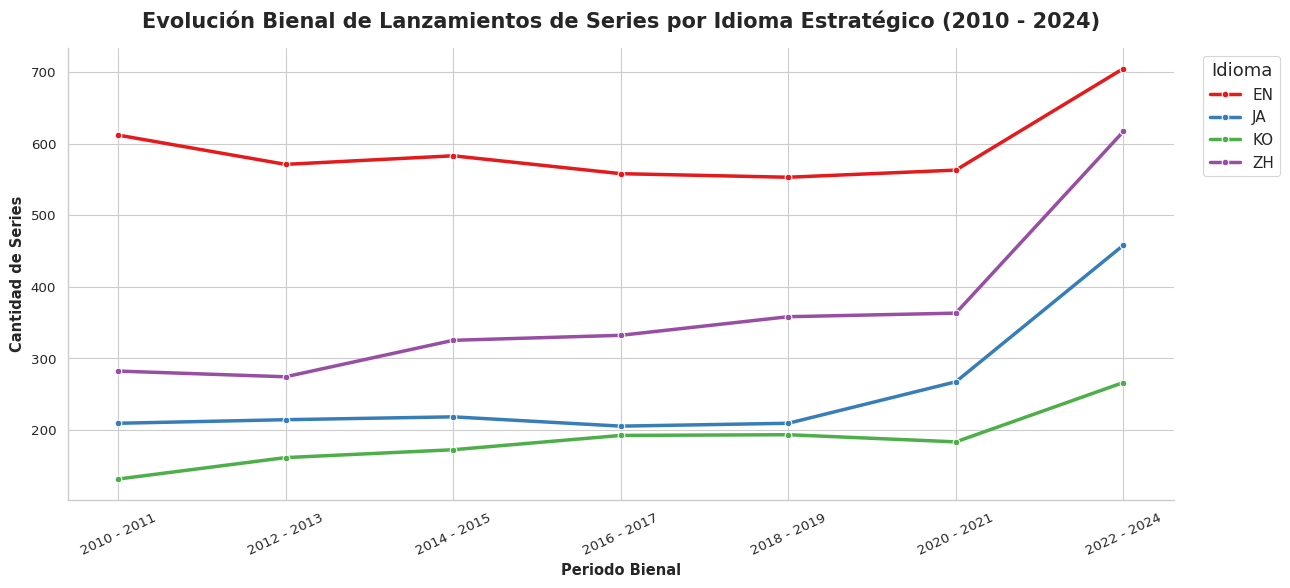

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# 1. Eliminar nulos en las columnas clave de series
df_s = df_series.dropna(subset=['release_year', 'language']).copy()

# Asegurar el año como número y filtrar estrictamente de 2010 a 2024
df_s['year_clean'] = pd.to_numeric(df_s['release_year'], errors='coerce')
df_s = df_s[(df_s['year_clean'] >= 2010) & (df_s['year_clean'] <= 2024)]

# Estandarización de idiomas a minúsculas
df_s['language'] = df_s['language'].astype(str).str.strip().str.lower()

# 2. Mapeo de códigos de idioma para agrupar variantes
condicion_en = df_s['language'].isin(['en', 'english'])
condicion_ja = df_s['language'].isin(['ja', 'jp', 'japanese'])
condicion_ko = df_s['language'].isin(['ko', 'korean'])
condicion_zh = df_s['language'].isin(['zh', 'cn', 'chinese', 'mandarin'])

df_s['Idioma_Mapeado'] = np.where(condicion_en, 'EN',
                         np.where(condicion_ja, 'JA',
                         np.where(condicion_ko, 'KO',
                         np.where(condicion_zh, 'ZH', None))))

# Filtrar solo los mapeados
df_s_filtrado = df_s[df_s['Idioma_Mapeado'].notnull()].copy()

if not df_s_filtrado.empty:
    # 3. Creación de rangos de 2 años (Bienales) desde 2010 hasta 2024
    bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
    labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

    df_s_filtrado['Rango_Anos'] = pd.cut(df_s_filtrado['year_clean'], bins=bins, labels=labels)

    # Agrupar por rango bienal e idioma mapeado sumando la cantidad de lanzamientos
    conteo_series = df_s_filtrado.groupby(['Rango_Anos', 'Idioma_Mapeado'], observed=False).size().reset_index(name='Cantidad')

    # 4. Generación de la gráfica de líneas bienal
    plt.figure(figsize=(13, 6))
    sns.lineplot(
        data=conteo_series,
        x='Rango_Anos',
        y='Cantidad',
        hue='Idioma_Mapeado',
        marker='o',
        linewidth=2.5,
        palette='Set1'
    )

    plt.title('Evolución Bienal de Lanzamientos de Series por Idioma Estratégico (2010 - 2024)', fontsize=15, weight='bold', pad=15)
    plt.xlabel('Periodo Bienal', weight='bold')
    plt.ylabel('Cantidad de Series', weight='bold')

    plt.legend(title='Idioma', title_fontsize='13', fontsize='11', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()
else:
    print("El gráfico está vacío. Los idiomas buscados no tienen coincidencias en el periodo.")

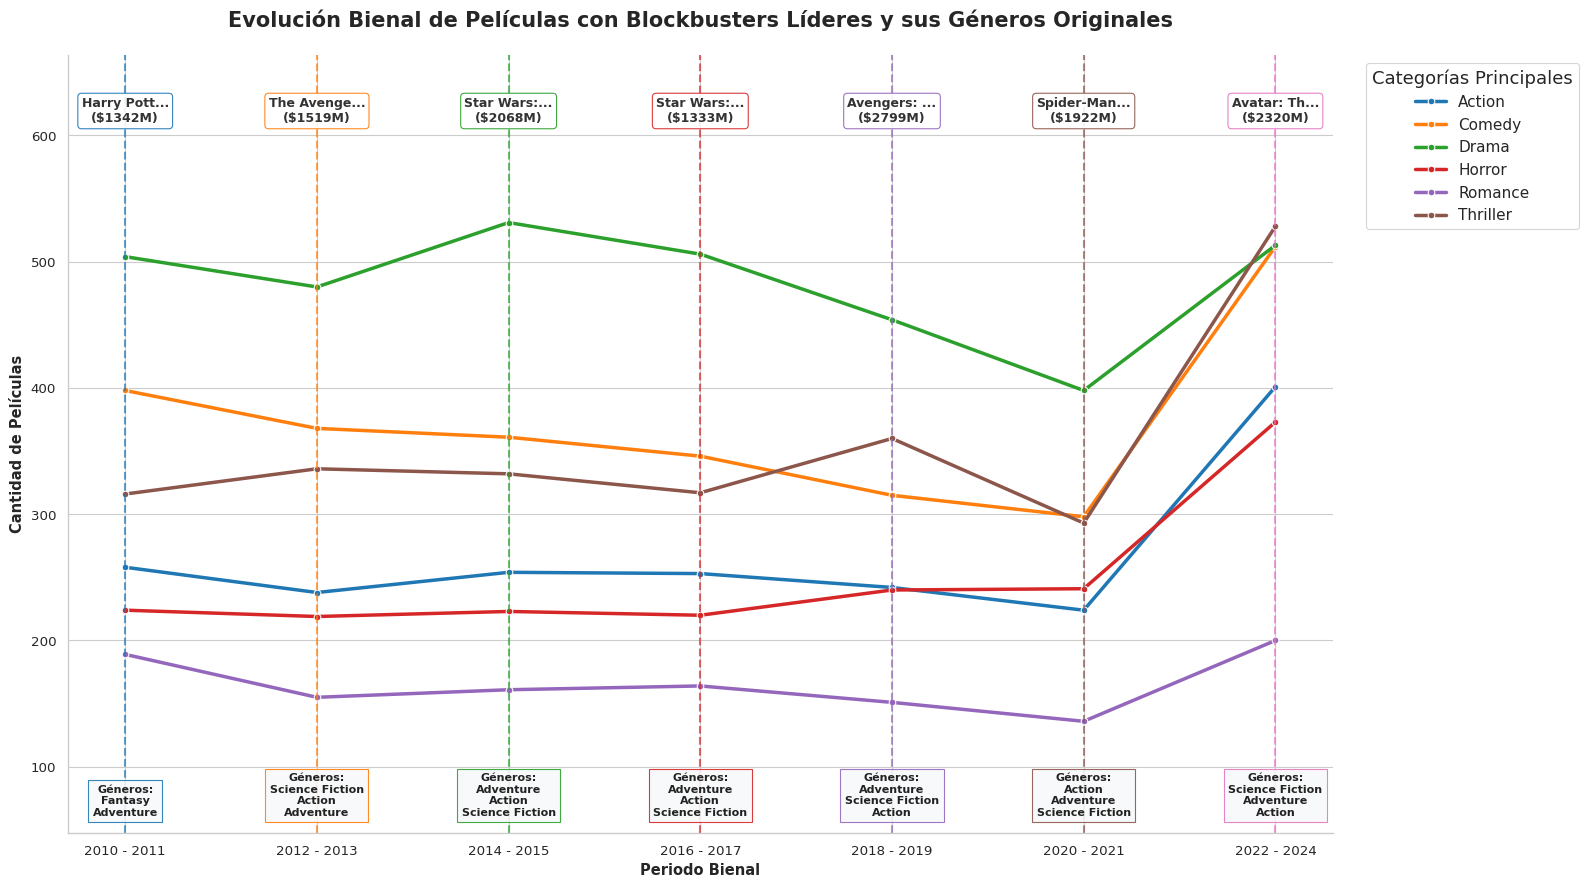

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# 1. Eliminar nulos en columnas clave de películas
df_p = df_peliculas.dropna(subset=['release_year', 'genres', 'language', 'title', 'revenue']).copy()

# 2. Filtro de idioma inglés y limpieza de años (2010 a 2024)
df_p['language'] = df_p['language'].astype(str).str.strip().str.lower()
df_p = df_p[df_p['language'].isin(['en', 'english'])]

df_p['year_clean'] = pd.to_numeric(df_p['release_year'], errors='coerce')
df_p = df_p[(df_p['year_clean'] >= 2010) & (df_p['year_clean'] <= 2024)]

# 3. Creación de rangos bienales (cada 2 años)
bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

df_p['Rango_Anos'] = pd.cut(df_p['year_clean'], bins=bins, labels=labels)

# 4. Separar películas con múltiples géneros para la gráfica principal
df_p_exploded_base = df_p.copy()
df_p_exploded_base['genres_list'] = df_p_exploded_base['genres'].astype(str).str.split(',')
df_exploded = df_p_exploded_base.explode('genres_list')
df_exploded['genres_list'] = df_exploded['genres_list'].str.strip()

top_categorias = df_exploded['genres_list'].value_counts().head(6).index.tolist()
df_top_cat = df_exploded[df_exploded['genres_list'].isin(top_categorias)].copy()

conteo_pelis = df_top_cat.groupby(['Rango_Anos', 'genres_list'], observed=False).size().reset_index(name='Cantidad')
conteo_pelis = conteo_pelis.rename(columns={'genres_list': 'genres'})

# 5. Generación del gráfico con mayor espacio vertical
plt.figure(figsize=(16, 9))
ax = sns.lineplot(
    data=conteo_pelis,
    x='Rango_Anos',
    y='Cantidad',
    hue='genres',
    marker='o',
    linewidth=2.5,
    palette='tab10'
)

y_min_real = conteo_pelis['Cantidad'].min()
y_max_real = conteo_pelis['Cantidad'].max()
plt.ylim(y_min_real * 0.35, y_max_real * 1.25)

colores_hitos = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']

for idx, etiqueta in enumerate(labels):
    subset_periodo = df_p[df_p['Rango_Anos'] == etiqueta]
    if not subset_periodo.empty:
        # Encontrar la película líder en recaudación del periodo
        top_pelicula = subset_periodo.loc[subset_periodo['revenue'].idxmax()]
        titulo_completo = str(top_pelicula['title'])
        titulo_corto = (titulo_completo[:10] + '...') if len(titulo_completo) > 10 else titulo_completo
        rev_M = top_pelicula['revenue'] / 1e6

        # Obtener los géneros reales de la película sin restricciones
        generos_crudos = str(top_pelicula['genres'])
        generos_pelicula = [g.strip() for g in generos_crudos.split(',') if g.strip()]
        texto_generos = "\n".join(generos_pelicula[:3]) if generos_pelicula else "N/A" # Muestra hasta 3 géneros principales

        color_linea = colores_hitos[idx % len(colores_hitos)]

        # Línea vertical guía
        plt.axvline(x=idx, color=color_linea, linestyle='--', linewidth=1.5, alpha=0.7)

        # Título y recaudación arriba
        plt.text(
            idx,
            y_max_real * 1.15,
            f"{titulo_corto}\n(${rev_M:.0f}M)",
            color='#333333',
            weight='bold',
            fontsize=9,
            ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=color_linea, alpha=0.9)
        )

        # Texto con los géneros reales abajo
        plt.text(
            idx,
            y_min_real * 0.45,
            f"Géneros:\n{texto_generos}",
            color='#222222',
            weight='bold',
            fontsize=8,
            ha='center',
            bbox=dict(boxstyle='square,pad=0.4', facecolor='#f8f9fa', edgecolor=color_linea, alpha=0.9)
        )

plt.title('Evolución Bienal de Películas con Blockbusters Líderes y sus Géneros Originales', fontsize=15, weight='bold', pad=20)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Cantidad de Películas', weight='bold')

plt.legend(title='Categorías Principales', title_fontsize='13', fontsize='11', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
df_peliculas[df_peliculas['title'] == 'Spider-Man: No Way Home']

,show_id,type,title,director,cast,country,date_added,release_year,rating,genres,language,description,popularity,vote_count,vote_average,budget,revenue
11000,634649,Movie,Spider-Man: No Way Home,Jon Watts,"Tom Holland, Zendaya, Benedict Cumberbatch, Ja...",United States of America,2021-12-15,2021,7.949,"Action, Adventure, Science Fiction",en,Peter Parker is unmasked and no longer able to...,169.128,20558,7.949,200000000,1921847111


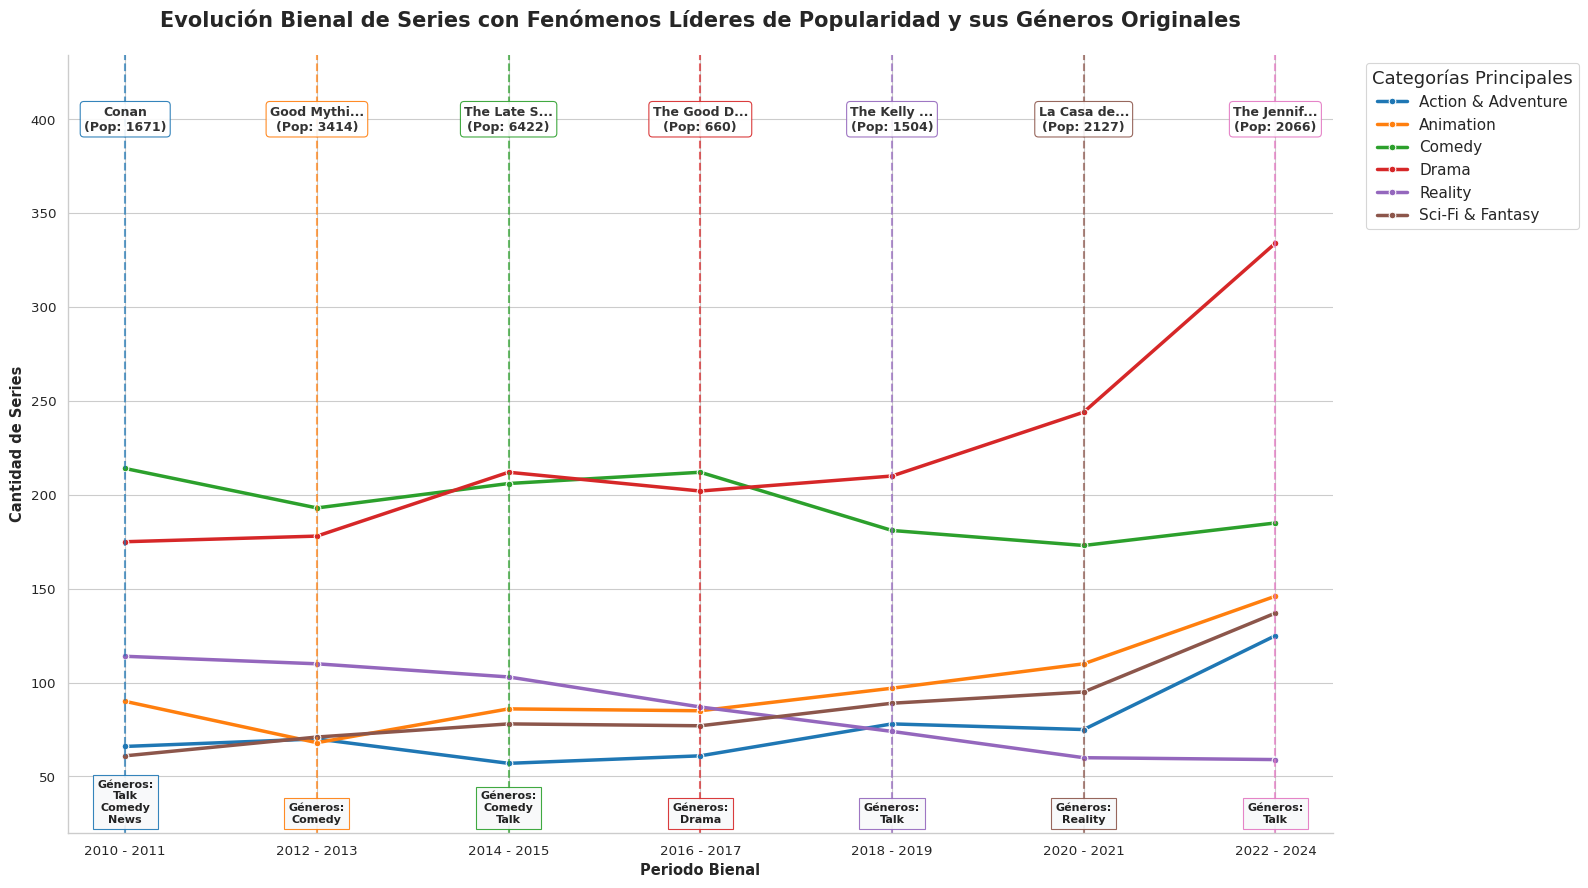

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# 1. Eliminar nulos en columnas clave de series (asegurando popularity, genres, release_year y title)
df_s = df_series.dropna(subset=['release_year', 'genres', 'language', 'title', 'popularity']).copy()

# 2. Filtro de idioma inglés y limpieza de años (2010 a 2024)
df_s['language'] = df_s['language'].astype(str).str.strip().str.lower()
df_s = df_s[df_s['language'].isin(['en', 'english'])]

df_s['year_clean'] = pd.to_numeric(df_s['release_year'], errors='coerce')
df_s = df_s[(df_s['year_clean'] >= 2010) & (df_s['year_clean'] <= 2024)]

# 3. Creación de rangos bienales (cada 2 años)
bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

df_s['Rango_Anos'] = pd.cut(df_s['year_clean'], bins=bins, labels=labels)

# 4. Separar series con múltiples géneros para la gráfica principal de líneas
df_s_exploded_base = df_s.copy()
df_s_exploded_base['genres_list'] = df_s_exploded_base['genres'].astype(str).str.split(',')
df_s_exploded = df_s_exploded_base.explode('genres_list')
df_s_exploded['genres_list'] = df_s_exploded['genres_list'].str.strip()

top_categorias_s = df_s_exploded['genres_list'].value_counts().head(6).index.tolist()
df_s_top_cat = df_s_exploded[df_s_exploded['genres_list'].isin(top_categorias_s)].copy()

conteo_series = df_s_top_cat.groupby(['Rango_Anos', 'genres_list'], observed=False).size().reset_index(name='Cantidad')
conteo_series = conteo_series.rename(columns={'genres_list': 'genres'})

# 5. Generación del gráfico con mayor espacio vertical
plt.figure(figsize=(16, 9))
ax = sns.lineplot(
    data=conteo_series,
    x='Rango_Anos',
    y='Cantidad',
    hue='genres',
    marker='o',
    linewidth=2.5,
    palette='tab10'
)

y_min_real = conteo_series['Cantidad'].min()
y_max_real = conteo_series['Cantidad'].max()
plt.ylim(y_min_real * 0.35, y_max_real * 1.30)

colores_hitos = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2']

for idx, etiqueta in enumerate(labels):
    subset_periodo = df_s[df_s['Rango_Anos'] == etiqueta]
    if not subset_periodo.empty:
        # Encontrar la serie líder en popularidad dentro del periodo bienal
        top_serie = subset_periodo.loc[subset_periodo['popularity'].idxmax()]
        titulo_completo = str(top_serie['title'])
        titulo_corto = (titulo_completo[:10] + '...') if len(titulo_completo) > 10 else titulo_completo
        pop_score = top_serie['popularity']

        # Obtener los géneros originales de la serie sin restricciones
        generos_crudos = str(top_serie['genres'])
        generos_serie = [g.strip() for g in generos_crudos.split(',') if g.strip()]
        texto_generos = "\n".join(generos_serie[:3]) if generos_serie else "N/A"

        color_linea = colores_hitos[idx % len(colores_hitos)]

        # Línea vertical guía
        plt.axvline(x=idx, color=color_linea, linestyle='--', linewidth=1.5, alpha=0.7)

        # Título y puntaje de popularidad arriba
        plt.text(
            idx,
            y_max_real * 1.18,
            f"{titulo_corto}\n(Pop: {pop_score:.0f})",
            color='#333333',
            weight='bold',
            fontsize=9,
            ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor=color_linea, alpha=0.9)
        )

        # Texto con los géneros reales abajo
        plt.text(
            idx,
            y_min_real * 0.45,
            f"Géneros:\n{texto_generos}",
            color='#222222',
            weight='bold',
            fontsize=8,
            ha='center',
            bbox=dict(boxstyle='square,pad=0.4', facecolor='#f8f9fa', edgecolor=color_linea, alpha=0.9)
        )

plt.title('Evolución Bienal de Series con Fenómenos Líderes de Popularidad y sus Géneros Originales', fontsize=15, weight='bold', pad=20)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Cantidad de Series', weight='bold')

plt.legend(title='Categorías Principales', title_fontsize='13', fontsize='11', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

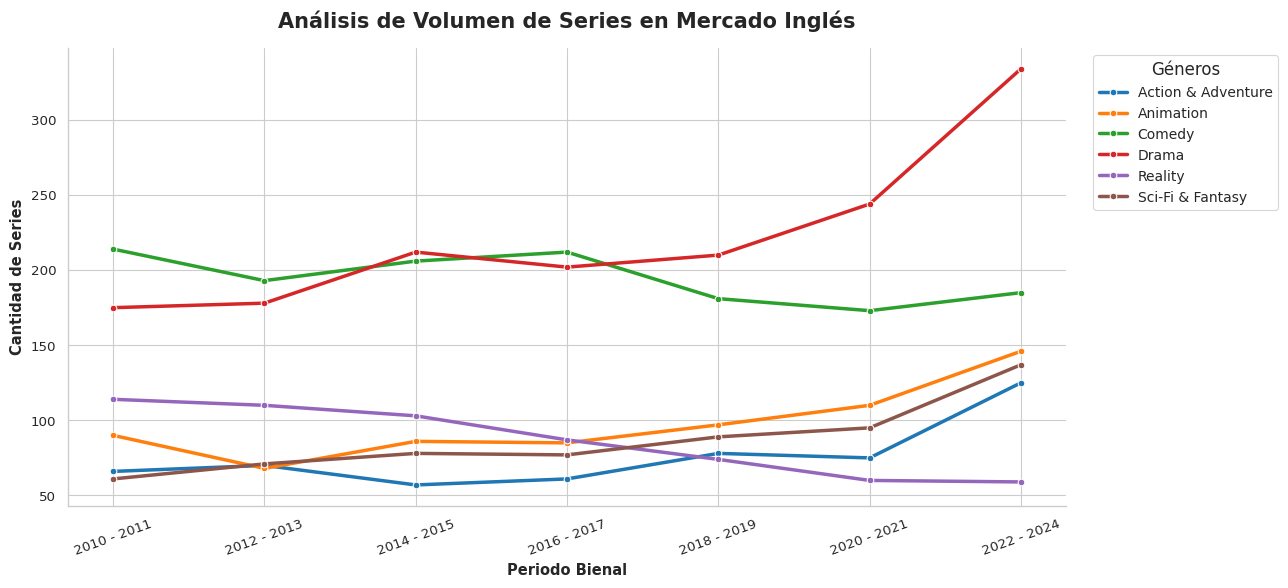

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# 1. Preparar datos de series en inglés
df_s_en = df_series.dropna(subset=['release_year', 'genres', 'language']).copy()
df_s_en['language'] = df_s_en['language'].astype(str).str.strip().str.lower()
df_s_en = df_s_en[df_s_en['language'].isin(['en', 'english'])]

df_s_en['year_clean'] = pd.to_numeric(df_s_en['release_year'], errors='coerce')
df_s_en = df_s_en[(df_s_en['year_clean'] >= 2010) & (df_s_en['year_clean'] <= 2024)]

# 2. Rangos bienales
bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']
df_s_en['Rango_Anos'] = pd.cut(df_s_en['year_clean'], bins=bins, labels=labels)

# 3. Explotar géneros y calcular volumen
df_s_exp = df_s_en.copy()
df_s_exp['genres_list'] = df_s_exp['genres'].astype(str).str.split(',')
df_s_exp = df_s_exp.explode('genres_list')
df_s_exp['genres_list'] = df_s_exp['genres_list'].str.strip()

top_cat = df_s_exp['genres_list'].value_counts().head(6).index.tolist()
df_top = df_s_exp[df_s_exp['genres_list'].isin(top_cat)].copy()

volumen_en = df_top.groupby(['Rango_Anos', 'genres_list'], observed=False).size().reset_index(name='Cantidad')

# 4. Gráfico
plt.figure(figsize=(13, 6))
sns.lineplot(
    data=volumen_en, x='Rango_Anos', y='Cantidad', hue='genres_list',
    marker='o', linewidth=2.5, palette='tab10'
)

plt.title('Análisis de Volumen de Series en Mercado Inglés', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Cantidad de Series', weight='bold')
plt.legend(title='Géneros', title_fontsize='12', fontsize='10', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

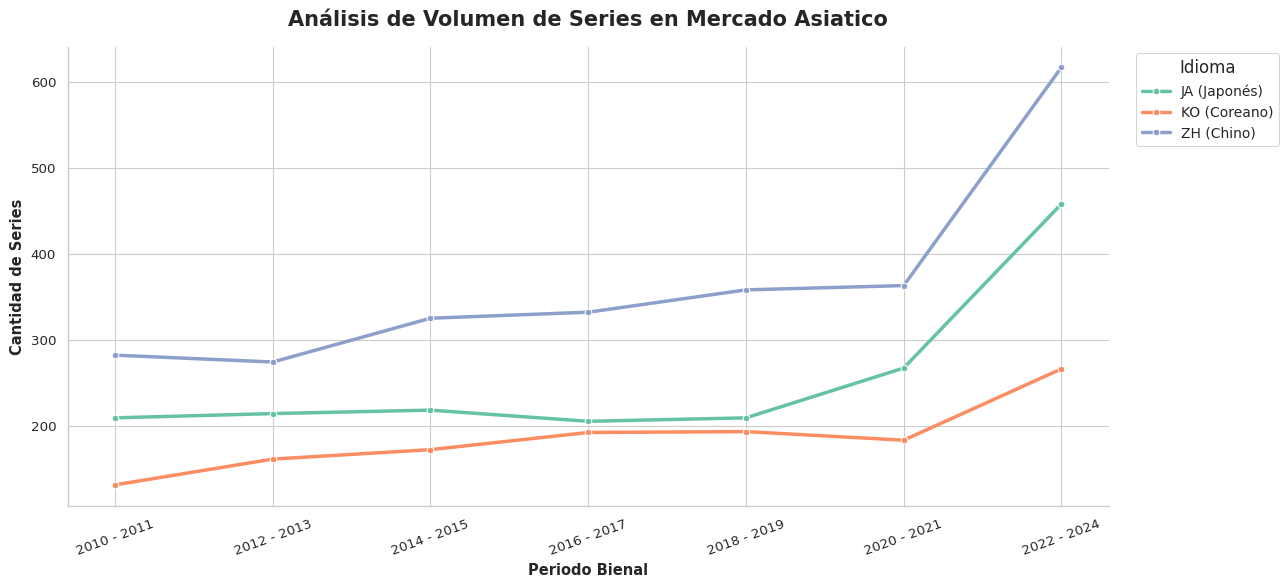

In [ ]:
# 1. Preparar datos de series asiáticas
df_s_as = df_series.dropna(subset=['release_year', 'genres', 'language']).copy()
df_s_as['language'] = df_s_as['language'].astype(str).str.strip().str.lower()

cond_ja = df_s_as['language'].isin(['ja', 'jp', 'japanese'])
cond_ko = df_s_as['language'].isin(['ko', 'korean'])
cond_zh = df_s_as['language'].isin(['zh', 'cn', 'chinese', 'mandarin'])

df_s_as['Idioma_Asiatico'] = np.where(cond_ja, 'JA (Japonés)',
                             np.where(cond_ko, 'KO (Coreano)',
                             np.where(cond_zh, 'ZH (Chino)', None)))

df_s_as = df_s_as[df_s_as['Idioma_Asiatico'].notnull()].copy()
df_s_as['year_clean'] = pd.to_numeric(df_s_as['release_year'], errors='coerce')
df_s_as = df_s_as[(df_s_as['year_clean'] >= 2010) & (df_s_as['year_clean'] <= 2024)]
df_s_as['Rango_Anos'] = pd.cut(df_s_as['year_clean'], bins=bins, labels=labels)

volumen_asiatico = df_s_as.groupby(['Rango_Anos', 'Idioma_Asiatico'], observed=False).size().reset_index(name='Cantidad')

# 2. Gráfico
plt.figure(figsize=(13, 6))
sns.lineplot(
    data=volumen_asiatico, x='Rango_Anos', y='Cantidad', hue='Idioma_Asiatico',
    marker='o', linewidth=2.5, palette='Set2'
)

plt.title('Análisis de Volumen de Series en Mercado Asiatico', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Cantidad de Series', weight='bold')
plt.legend(title='Idioma', title_fontsize='12', fontsize='10', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

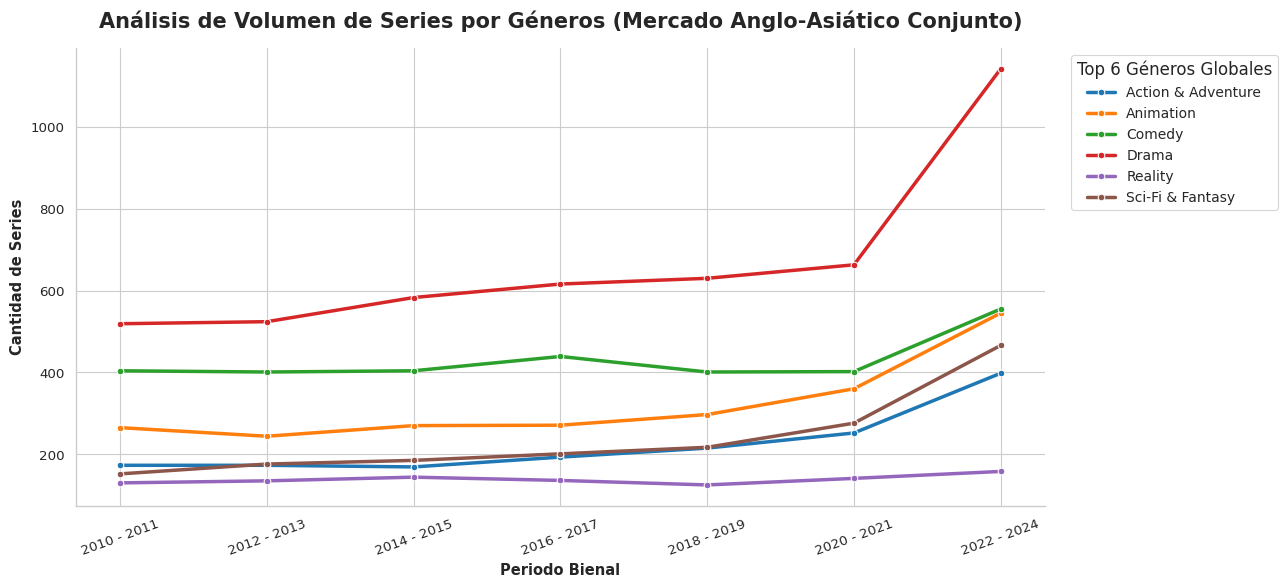

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

# 1. Preparar datos base de series y filtrar por el grupo de estudio unificado
df_s = df_series.dropna(subset=['release_year', 'genres', 'language']).copy()
df_s['language'] = df_s['language'].astype(str).str.strip().str.lower()

# Definir el mercado conjunto (Inglés + Japonés, Coreano, Chino)
idiomas_objetivo = ['en', 'english', 'ja', 'jp', 'japanese', 'ko', 'korean', 'zh', 'cn', 'chinese', 'mandarin']
df_s = df_s[df_s['language'].isin(idiomas_objetivo)].copy()

# Limpieza de fechas y rangos bienales
df_s['year_clean'] = pd.to_numeric(df_s['release_year'], errors='coerce')
df_s = df_s[(df_s['year_clean'] >= 2010) & (df_s['year_clean'] <= 2024)]
df_s['Rango_Anos'] = pd.cut(df_s['year_clean'], bins=bins, labels=labels)

# 2. Separar series con múltiples géneros
df_s_exp = df_s.copy()
df_s_exp['genres_list'] = df_s_exp['genres'].astype(str).str.split(',')
df_s_exp = df_s_exp.explode('genres_list')
df_s_exp['genres_list'] = df_s_exp['genres_list'].str.strip()

# 3. Identificar el Top 6 de géneros en este mercado unificado Anglo-Asiático
top_cat = df_s_exp['genres_list'].value_counts().head(6).index.tolist()
df_top = df_s_exp[df_s_exp['genres_list'].isin(top_cat)].copy()

# Calcular volumen
volumen_conjunto = df_top.groupby(['Rango_Anos', 'genres_list'], observed=False).size().reset_index(name='Cantidad')

# 4. Generación del gráfico
plt.figure(figsize=(13, 6))
sns.lineplot(
    data=volumen_conjunto,
    x='Rango_Anos',
    y='Cantidad',
    hue='genres_list',
    marker='o',
    linewidth=2.5,
    palette='tab10'
)

plt.title('Análisis de Volumen de Series por Géneros (Mercado Anglo-Asiático Conjunto)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Cantidad de Series', weight='bold')
plt.legend(title='Top 6 Géneros Globales', title_fontsize='12', fontsize='10', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

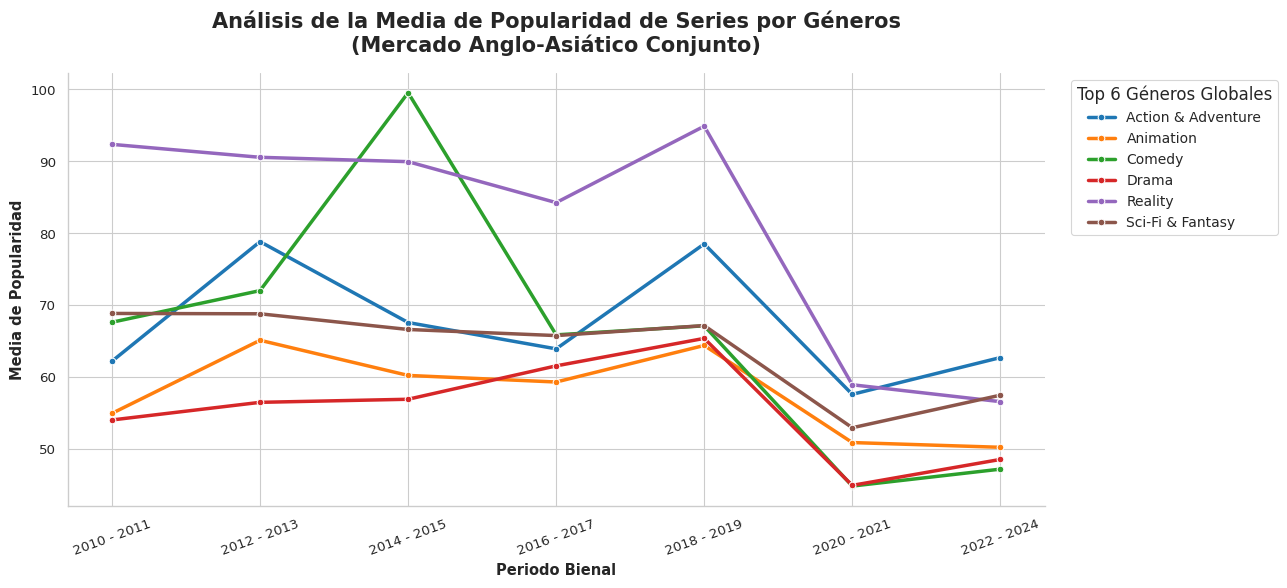

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

# 1. Preparar datos base de series (asegurando que exista la columna popularity)
df_s = df_series.dropna(subset=['release_year', 'genres', 'language', 'popularity']).copy()
df_s['language'] = df_s['language'].astype(str).str.strip().str.lower()

# Definir el mercado conjunto (Inglés + Japonés, Coreano, Chino)
idiomas_objetivo = ['en', 'english', 'ja', 'jp', 'japanese', 'ko', 'korean', 'zh', 'cn', 'chinese', 'mandarin']
df_s = df_s[df_s['language'].isin(idiomas_objetivo)].copy()

# Limpieza de fechas y rangos bienales
df_s['year_clean'] = pd.to_numeric(df_s['release_year'], errors='coerce')
df_s = df_s[(df_s['year_clean'] >= 2010) & (df_s['year_clean'] <= 2024)]
df_s['Rango_Anos'] = pd.cut(df_s['year_clean'], bins=bins, labels=labels)

# 2. Separar series con múltiples géneros
df_s_exp = df_s.copy()
df_s_exp['genres_list'] = df_s_exp['genres'].astype(str).str.split(',')
df_s_exp = df_s_exp.explode('genres_list')
df_s_exp['genres_list'] = df_s_exp['genres_list'].str.strip()

# 3. Identificar el Top 6 de géneros en este mercado unificado Anglo-Asiático
top_cat = df_s_exp['genres_list'].value_counts().head(6).index.tolist()
df_top = df_s_exp[df_s_exp['genres_list'].isin(top_cat)].copy()

# 4. Calcular la MEDIA DE POPULARIDAD por rango y género
media_conjunta = df_top.groupby(['Rango_Anos', 'genres_list'], observed=False)['popularity'].mean().reset_index(name='Media_Popularidad')

# 5. Generación del gráfico
plt.figure(figsize=(13, 6))
sns.lineplot(
    data=media_conjunta,
    x='Rango_Anos',
    y='Media_Popularidad',
    hue='genres_list',
    marker='o',
    linewidth=2.5,
    palette='tab10'
)

plt.title('Análisis de la Media de Popularidad de Series por Géneros\n(Mercado Anglo-Asiático Conjunto)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Media de Popularidad', weight='bold')
plt.legend(title='Top 6 Géneros Globales', title_fontsize='12', fontsize='10', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

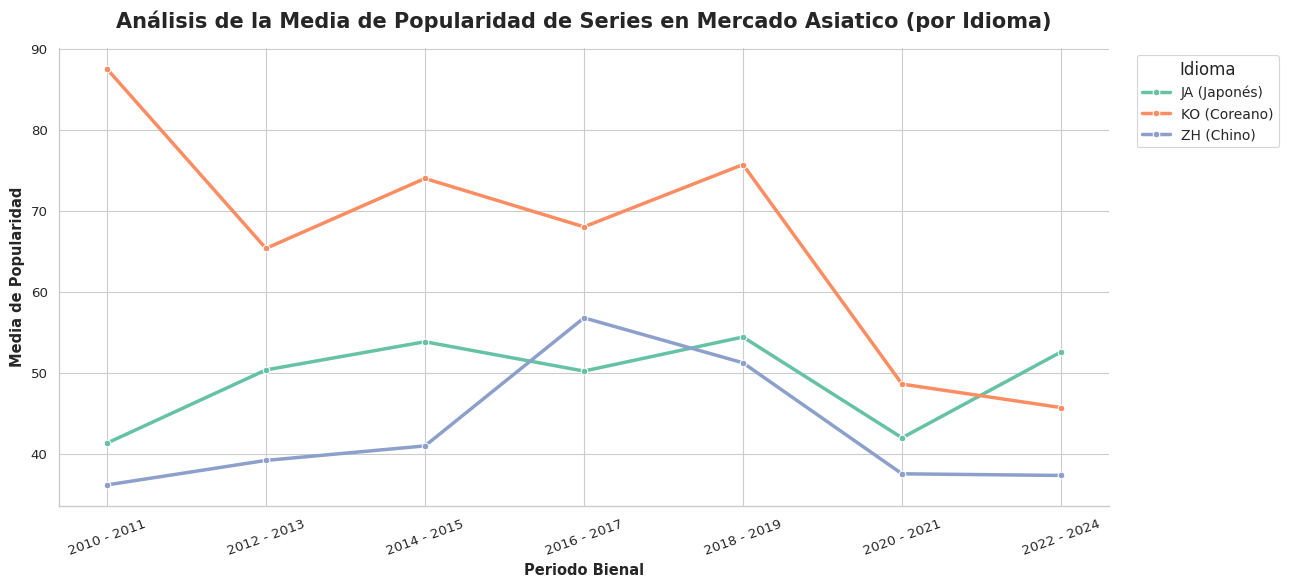

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

# 1. Preparar datos de series y filtrar nulos clave
df_s_as = df_series.dropna(subset=['release_year', 'language', 'popularity']).copy()
df_s_as['language'] = df_s_as['language'].astype(str).str.strip().str.lower()

# 2. Mapeo explícito de códigos de idioma asiático
cond_ja = df_s_as['language'].isin(['ja', 'jp', 'japanese'])
cond_ko = df_s_as['language'].isin(['ko', 'korean'])
cond_zh = df_s_as['language'].isin(['zh', 'cn', 'chinese', 'mandarin'])

df_s_as['Idioma_Agrupado'] = np.where(cond_ja, 'JA (Japonés)',
                             np.where(cond_ko, 'KO (Coreano)',
                             np.where(cond_zh, 'ZH (Chino)', None)))

# Filtrar solo los registros que coincidan con estos idiomas
df_s_as = df_s_as[df_s_as['Idioma_Agrupado'].notnull()].copy()

# 3. Limpieza de años y asignación de rangos bienales
df_s_as['year_clean'] = pd.to_numeric(df_s_as['release_year'], errors='coerce')
df_s_as = df_s_as[(df_s_as['year_clean'] >= 2010) & (df_s_as['year_clean'] <= 2024)]
df_s_as['Rango_Anos'] = pd.cut(df_s_as['year_clean'], bins=bins, labels=labels)

# 4. Calcular la media de popularidad por rango y por cada idioma agrupado
media_asiatico = df_s_as.groupby(['Rango_Anos', 'Idioma_Agrupado'], observed=False)['popularity'].mean().reset_index(name='Media_Popularidad')

# 5. Generación del gráfico
plt.figure(figsize=(13, 6))
sns.lineplot(
    data=media_asiatico,
    x='Rango_Anos',
    y='Media_Popularidad',
    hue='Idioma_Agrupado',
    marker='o',
    linewidth=2.5,
    palette='Set2'
)

plt.title('Análisis de la Media de Popularidad de Series en Mercado Asiatico (por Idioma)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Media de Popularidad', weight='bold')

plt.legend(title='Idioma', title_fontsize='12', fontsize='10', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

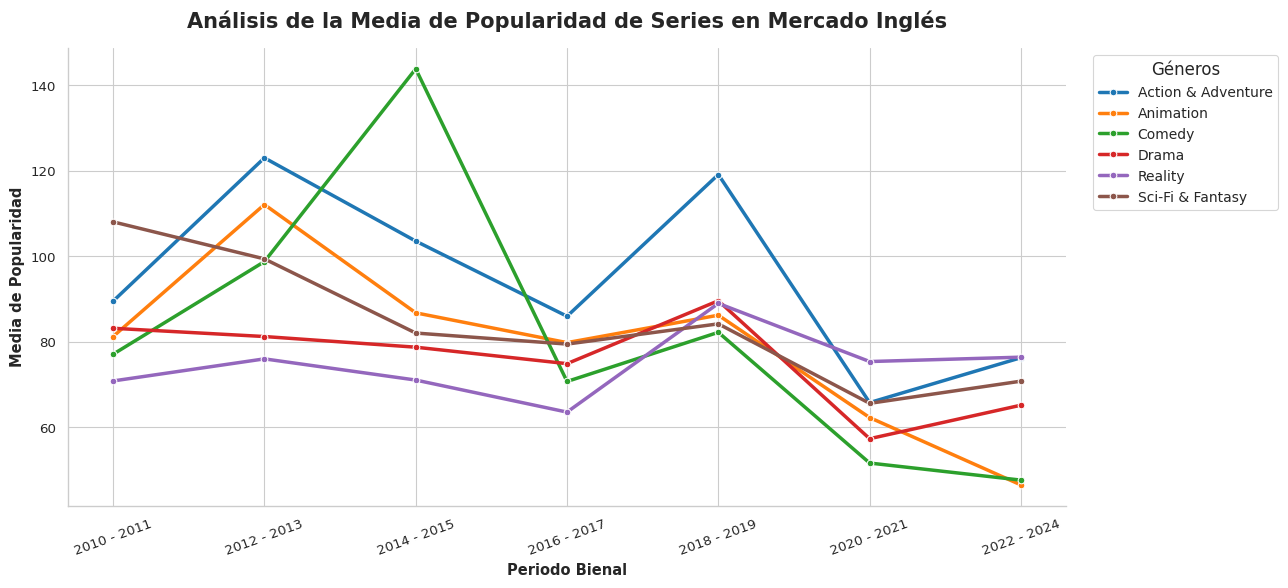

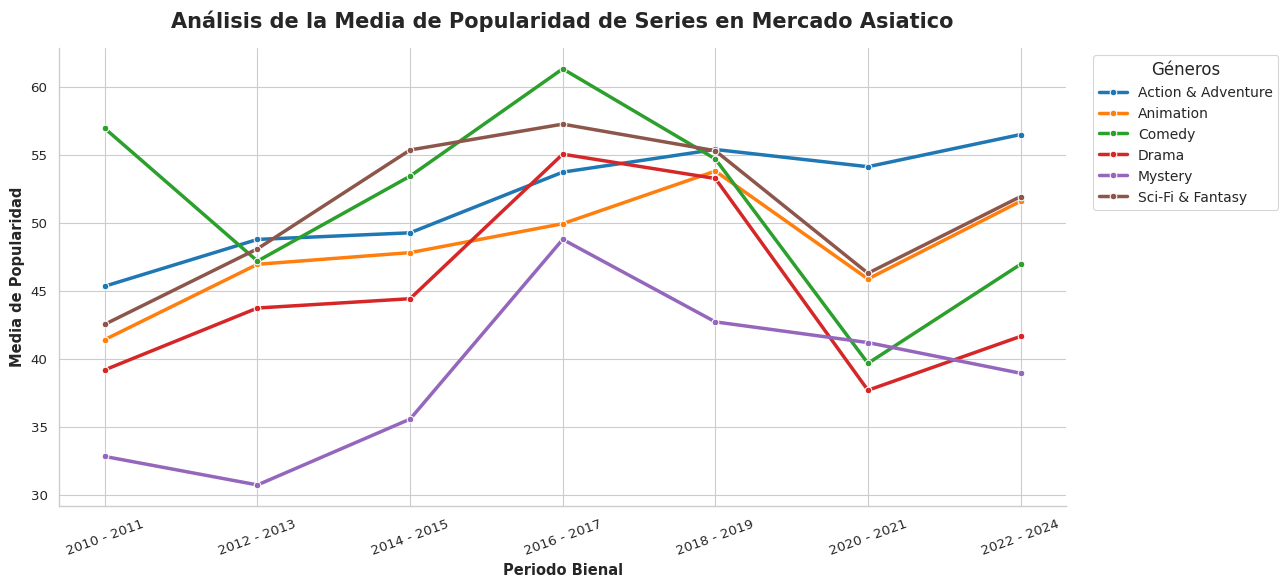

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

# --- 1. MERCADO INGLÉS: Media de Popularidad por Géneros ---
df_s_en = df_series.dropna(subset=['release_year', 'genres', 'language', 'popularity']).copy()
df_s_en['language'] = df_s_en['language'].astype(str).str.strip().str.lower()
df_s_en = df_s_en[df_s_en['language'].isin(['en', 'english'])]
df_s_en['year_clean'] = pd.to_numeric(df_s_en['release_year'], errors='coerce')
df_s_en = df_s_en[(df_s_en['year_clean'] >= 2010) & (df_s_en['year_clean'] <= 2024)]
df_s_en['Rango_Anos'] = pd.cut(df_s_en['year_clean'], bins=bins, labels=labels)

df_s_en_exp = df_s_en.copy()
df_s_en_exp['genres_list'] = df_s_en_exp['genres'].astype(str).str.split(',')
df_s_en_exp = df_s_en_exp.explode('genres_list')
df_s_en_exp['genres_list'] = df_s_en_exp['genres_list'].str.strip()

top_cat_en = df_s_en_exp['genres_list'].value_counts().head(6).index.tolist()
df_top_en = df_s_en_exp[df_s_en_exp['genres_list'].isin(top_cat_en)].copy()
media_en = df_top_en.groupby(['Rango_Anos', 'genres_list'], observed=False)['popularity'].mean().reset_index(name='Media_Popularidad')

plt.figure(figsize=(13, 6))
sns.lineplot(data=media_en, x='Rango_Anos', y='Media_Popularidad', hue='genres_list', marker='o', linewidth=2.5, palette='tab10')
plt.title('Análisis de la Media de Popularidad de Series en Mercado Inglés', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Media de Popularidad', weight='bold')
plt.legend(title='Géneros', title_fontsize='12', fontsize='10', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# --- 2. MERCADO ASIÁTICO: Media de Popularidad por Géneros ---
df_s_as = df_series.dropna(subset=['release_year', 'genres', 'language', 'popularity']).copy()
df_s_as['language'] = df_s_as['language'].astype(str).str.strip().str.lower()

cond_asiatico = df_s_as['language'].isin(['ja', 'jp', 'japanese', 'ko', 'korean', 'zh', 'cn', 'chinese', 'mandarin'])
df_s_as = df_s_as[cond_asiatico].copy()

df_s_as['year_clean'] = pd.to_numeric(df_s_as['release_year'], errors='coerce')
df_s_as = df_s_as[(df_s_as['year_clean'] >= 2010) & (df_s_as['year_clean'] <= 2024)]
df_s_as['Rango_Anos'] = pd.cut(df_s_as['year_clean'], bins=bins, labels=labels)

df_s_as_exp = df_s_as.copy()
df_s_as_exp['genres_list'] = df_s_as_exp['genres'].astype(str).str.split(',')
df_s_as_exp = df_s_as_exp.explode('genres_list')
df_s_as_exp['genres_list'] = df_s_as_exp['genres_list'].str.strip()

top_cat_as = df_s_as_exp['genres_list'].value_counts().head(6).index.tolist()
df_top_as = df_s_as_exp[df_s_as_exp['genres_list'].isin(top_cat_as)].copy()
media_as = df_top_as.groupby(['Rango_Anos', 'genres_list'], observed=False)['popularity'].mean().reset_index(name='Media_Popularidad')

plt.figure(figsize=(13, 6))
sns.lineplot(data=media_as, x='Rango_Anos', y='Media_Popularidad', hue='genres_list', marker='o', linewidth=2.5, palette='tab10')
plt.title('Análisis de la Media de Popularidad de Series en Mercado Asiatico', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Media de Popularidad', weight='bold')
plt.legend(title='Géneros', title_fontsize='12', fontsize='10', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

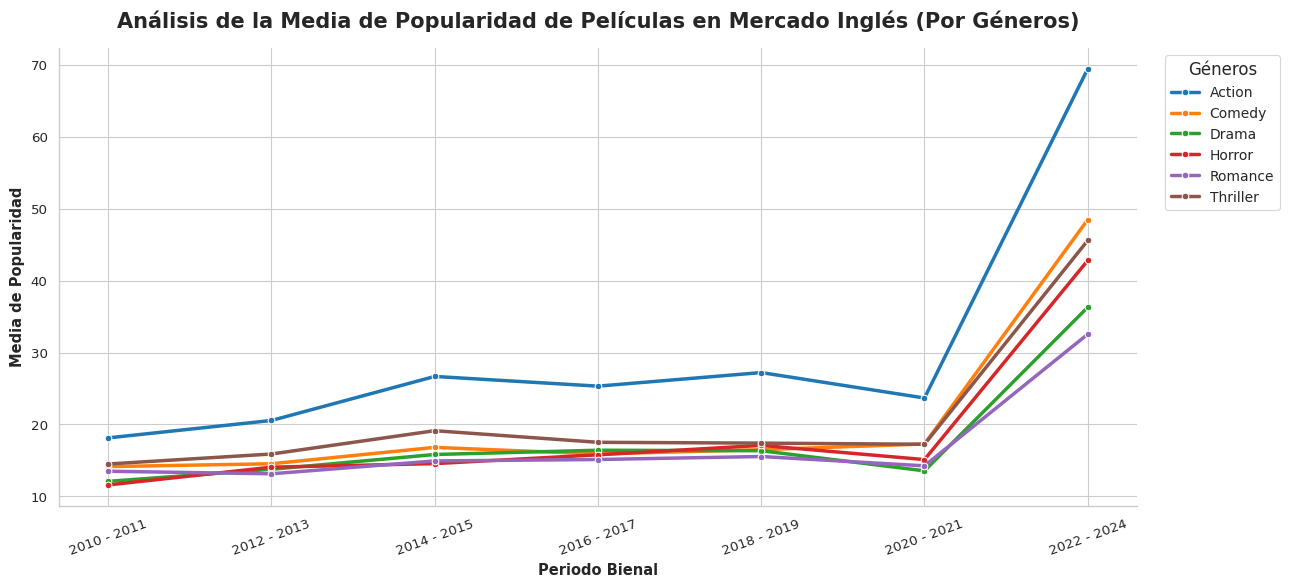

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

# 1. Preparar datos de películas en inglés (filtrando nulos en columnas clave y popularidad)
df_p = df_peliculas.dropna(subset=['release_year', 'genres', 'language', 'popularity']).copy()
df_p['language'] = df_p['language'].astype(str).str.strip().str.lower()
df_p = df_p[df_p['language'].isin(['en', 'english'])]

df_p['year_clean'] = pd.to_numeric(df_p['release_year'], errors='coerce')
df_p = df_p[(df_p['year_clean'] >= 2010) & (df_p['year_clean'] <= 2024)]
df_p['Rango_Anos'] = pd.cut(df_p['year_clean'], bins=bins, labels=labels)

# 2. Separar películas con múltiples géneros
df_p_exp = df_p.copy()
df_p_exp['genres_list'] = df_p_exp['genres'].astype(str).str.split(',')
df_p_exp = df_p_exp.explode('genres_list')
df_p_exp['genres_list'] = df_p_exp['genres_list'].str.strip()

# Identificar el Top 6 de géneros en películas
top_cat_p = df_p_exp['genres_list'].value_counts().head(6).index.tolist()
df_top_p = df_p_exp[df_p_exp['genres_list'].isin(top_cat_p)].copy()

# 3. Calcular la media de popularidad por rango bienal y género
media_pelis_en = df_top_p.groupby(['Rango_Anos', 'genres_list'], observed=False)['popularity'].mean().reset_index(name='Media_Popularidad')

# 4. Generación del gráfico
plt.figure(figsize=(13, 6))
sns.lineplot(
    data=media_pelis_en,
    x='Rango_Anos',
    y='Media_Popularidad',
    hue='genres_list',
    marker='o',
    linewidth=2.5,
    palette='tab10'
)

plt.title('Análisis de la Media de Popularidad de Películas en Mercado Inglés (Por Géneros)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Media de Popularidad', weight='bold')

plt.legend(title='Géneros', title_fontsize='12', fontsize='10', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

/tmp/ipykernel_3449/362951276.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


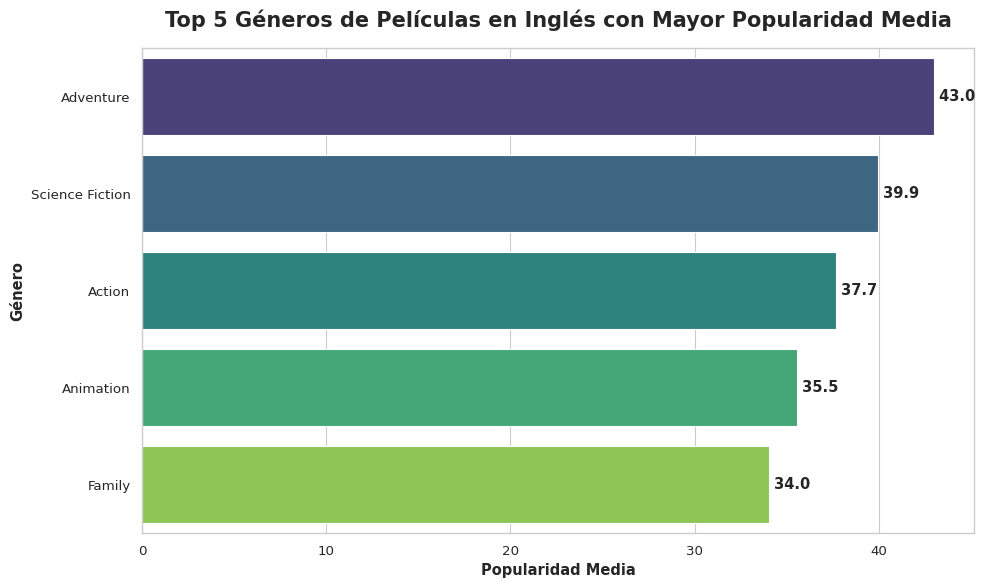

         genres  Popularidad_Media  Cantidad_Peliculas
      Adventure          43.006524                1083
Science Fiction          39.929508                1082
         Action          37.660107                1929
      Animation          35.536144                 839
         Family          34.009947                1047


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

# Eliminar nulos en columnas clave de películas, asegurando incluir 'language'
df_p = df_peliculas.dropna(subset=['genres', 'popularity', 'language']).copy()

# --- NUEVO FILTRO: Solo idioma Inglés ---
df_p['language'] = df_p['language'].astype(str).str.strip().str.lower()
df_p = df_p[df_p['language'].isin(['en', 'english'])]

# Separar películas con múltiples géneros
df_p['genres'] = df_p['genres'].astype(str).str.split(',')
df_p_exploded = df_p.explode('genres')
df_p_exploded['genres'] = df_p_exploded['genres'].str.strip()

# Agrupar por género para calcular la media de popularidad y contar las películas
stats_generos = df_p_exploded.groupby('genres').agg(
    Popularidad_Media=('popularity', 'mean'),
    Cantidad_Peliculas=('popularity', 'count')
).reset_index()

# Filtrar para considerar solo géneros con una muestra representativa (ej. mínimo 50 películas)
stats_generos = stats_generos[stats_generos['Cantidad_Peliculas'] >= 50]

# Ordenar de mayor a menor según la popularidad media y extraer el Top 5
top5_generos = stats_generos.sort_values(by='Popularidad_Media', ascending=False).head(5)

if not top5_generos.empty:
    # Crear el gráfico
    plt.figure(figsize=(10, 6))

    # Gráfico de barras horizontales para facilitar la lectura de los nombres
    sns.barplot(
        data=top5_generos,
        x='Popularidad_Media',
        y='genres',
        palette='viridis'
    )

    plt.title('Top 5 Géneros de Películas en Inglés con Mayor Popularidad Media', fontsize=15, weight='bold', pad=15)
    plt.xlabel('Popularidad Media', weight='bold')
    plt.ylabel('Género', weight='bold')

    # Agregar los valores numéricos exactos al final de cada barra
    for index, value in enumerate(top5_generos['Popularidad_Media']):
        plt.text(value, index, f' {value:.1f}', va='center', weight='bold')

    plt.tight_layout()
    plt.show()

    # Imprimir la tabla en texto para revisión
    print(top5_generos.to_string(index=False))
else:
    print("No hay suficientes datos de películas en inglés para generar el gráfico.")

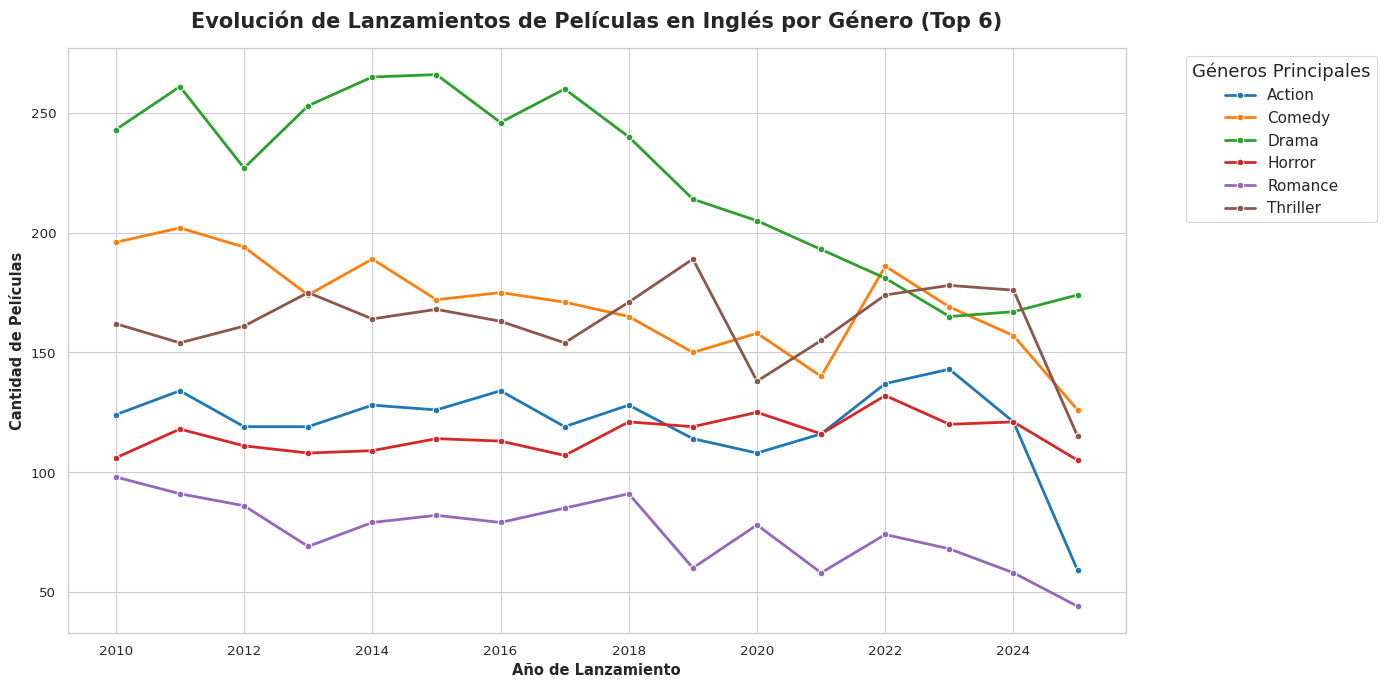

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

# Eliminar nulos en columnas clave de películas
df_p = df_peliculas.dropna(subset=['release_year', 'genres', 'language']).copy()

# --- FILTRO: Solo idioma Inglés ---
df_p['language'] = df_p['language'].astype(str).str.strip().str.lower()
df_p = df_p[df_p['language'].isin(['en', 'english'])]

# Asegurar que el año sea numérico y filtrar desde el 2000 para mayor claridad visual
df_p['year_clean'] = pd.to_numeric(df_p['release_year'], errors='coerce')
df_p = df_p[df_p['year_clean'] >= 2000]

# Separar películas con múltiples géneros
df_p['genres'] = df_p['genres'].astype(str).str.split(',')
df_p_exploded = df_p.explode('genres')
df_p_exploded['genres'] = df_p_exploded['genres'].str.strip()

# Identificar el Top 6 de géneros con más películas en inglés históricamente
top_categorias = df_p_exploded['genres'].value_counts().head(6).index.tolist()

# Filtrar para graficar solo el Top 6 (evita que el gráfico sea ilegible con docenas de líneas)
df_top_cat = df_p_exploded[df_p_exploded['genres'].isin(top_categorias)]

# Agrupar y contar cantidad de películas por año y género
conteo_pelis = df_top_cat.groupby(['year_clean', 'genres']).size().reset_index(name='Cantidad')

if not conteo_pelis.empty:
    plt.figure(figsize=(14, 7))
    sns.lineplot(
        data=conteo_pelis,
        x='year_clean',
        y='Cantidad',
        hue='genres',
        marker='o',
        linewidth=2,
        palette='tab10'
    )

    plt.title('Evolución de Lanzamientos de Películas en Inglés por Género (Top 6)', fontsize=15, weight='bold', pad=15)
    plt.xlabel('Año de Lanzamiento', weight='bold')
    plt.ylabel('Cantidad de Películas', weight='bold')

    plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.legend(title='Géneros Principales', title_fontsize='13', fontsize='11', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("No hay suficientes datos de películas en inglés con fechas y géneros válidos.")

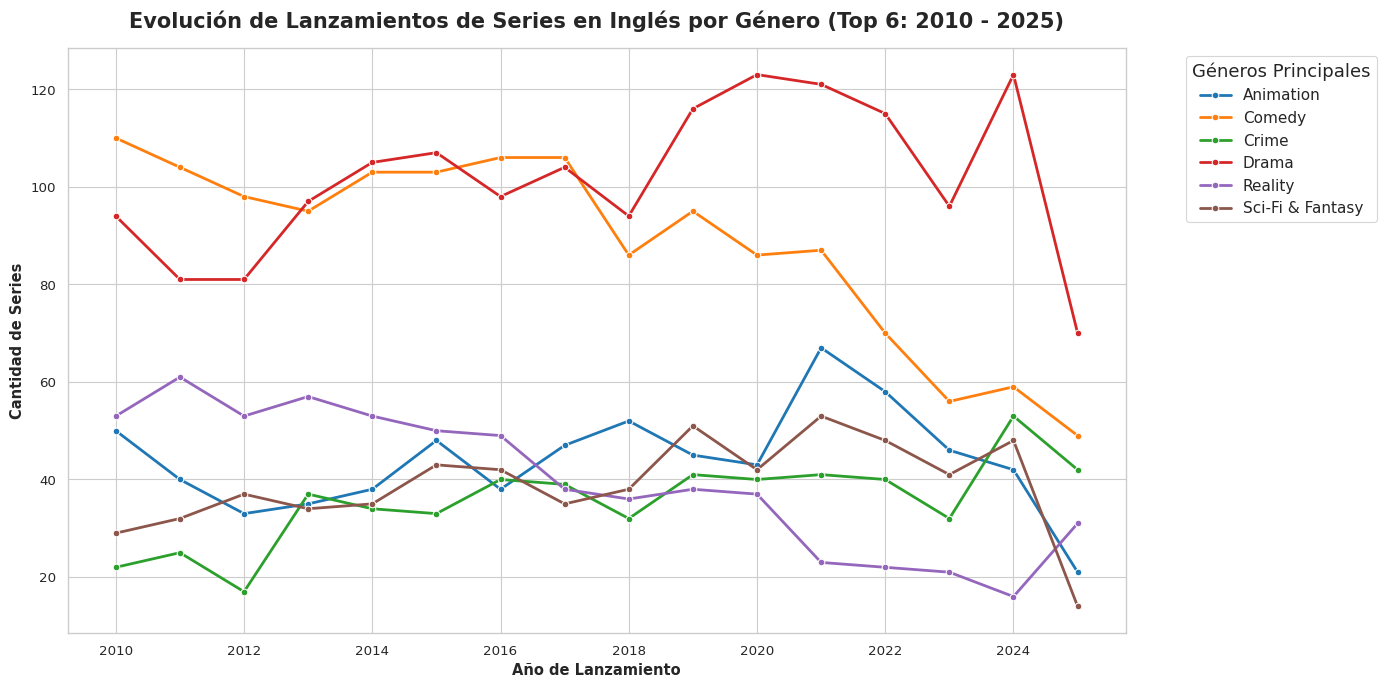

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

# Eliminar nulos en columnas clave de series
df_s = df_series.dropna(subset=['release_year', 'genres', 'language']).copy()

# --- FILTRO: Solo idioma Inglés ---
df_s['language'] = df_s['language'].astype(str).str.strip().str.lower()
df_s = df_s[df_s['language'].isin(['en', 'english'])]

# Asegurar que el año sea numérico y filtrar desde el 2010 hasta el 2025
df_s['year_clean'] = pd.to_numeric(df_s['release_year'], errors='coerce')
df_s = df_s[(df_s['year_clean'] >= 2010) & (df_s['year_clean'] <= 2025)]

# Separar series con múltiples géneros
df_s['genres'] = df_s['genres'].astype(str).str.split(',')
df_s_exploded = df_s.explode('genres')
df_s_exploded['genres'] = df_s_exploded['genres'].str.strip()

# Identificar el Top 6 de géneros con más series en inglés históricamente
top_categorias = df_s_exploded['genres'].value_counts().head(6).index.tolist()

# Filtrar para graficar solo el Top 6 (evita que el gráfico sea ilegible con demasiadas líneas)
df_top_cat = df_s_exploded[df_s_exploded['genres'].isin(top_categorias)]

# Agrupar y contar cantidad de series por año y género
conteo_series = df_top_cat.groupby(['year_clean', 'genres']).size().reset_index(name='Cantidad')

if not conteo_series.empty:
    plt.figure(figsize=(14, 7))
    sns.lineplot(
        data=conteo_series,
        x='year_clean',
        y='Cantidad',
        hue='genres',
        marker='o',
        linewidth=2,
        palette='tab10'
    )

    plt.title('Evolución de Lanzamientos de Series en Inglés por Género (Top 6: 2010 - 2025)', fontsize=15, weight='bold', pad=15)
    plt.xlabel('Año de Lanzamiento', weight='bold')
    plt.ylabel('Cantidad de Series', weight='bold')

    plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.legend(title='Géneros Principales', title_fontsize='13', fontsize='11', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("No hay suficientes datos de series en inglés con fechas y géneros válidos en este rango de tiempo.")

/tmp/ipykernel_3449/1501978410.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top5_cant, x='Cantidad', y='genres', ax=axes[i, 0], palette=color_cant)
/tmp/ipykernel_3449/1501978410.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top5_pop, x='popularity', y='genres', ax=axes[i, 1], palette=color_pop)
/tmp/ipykernel_3449/1501978410.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top5_cant, x='Cantidad', y='genres', ax=axes[i, 0], palette=color_cant)
/tmp/ipykernel_3449/1501978410.py:68: FutureWarning: 

Passing `

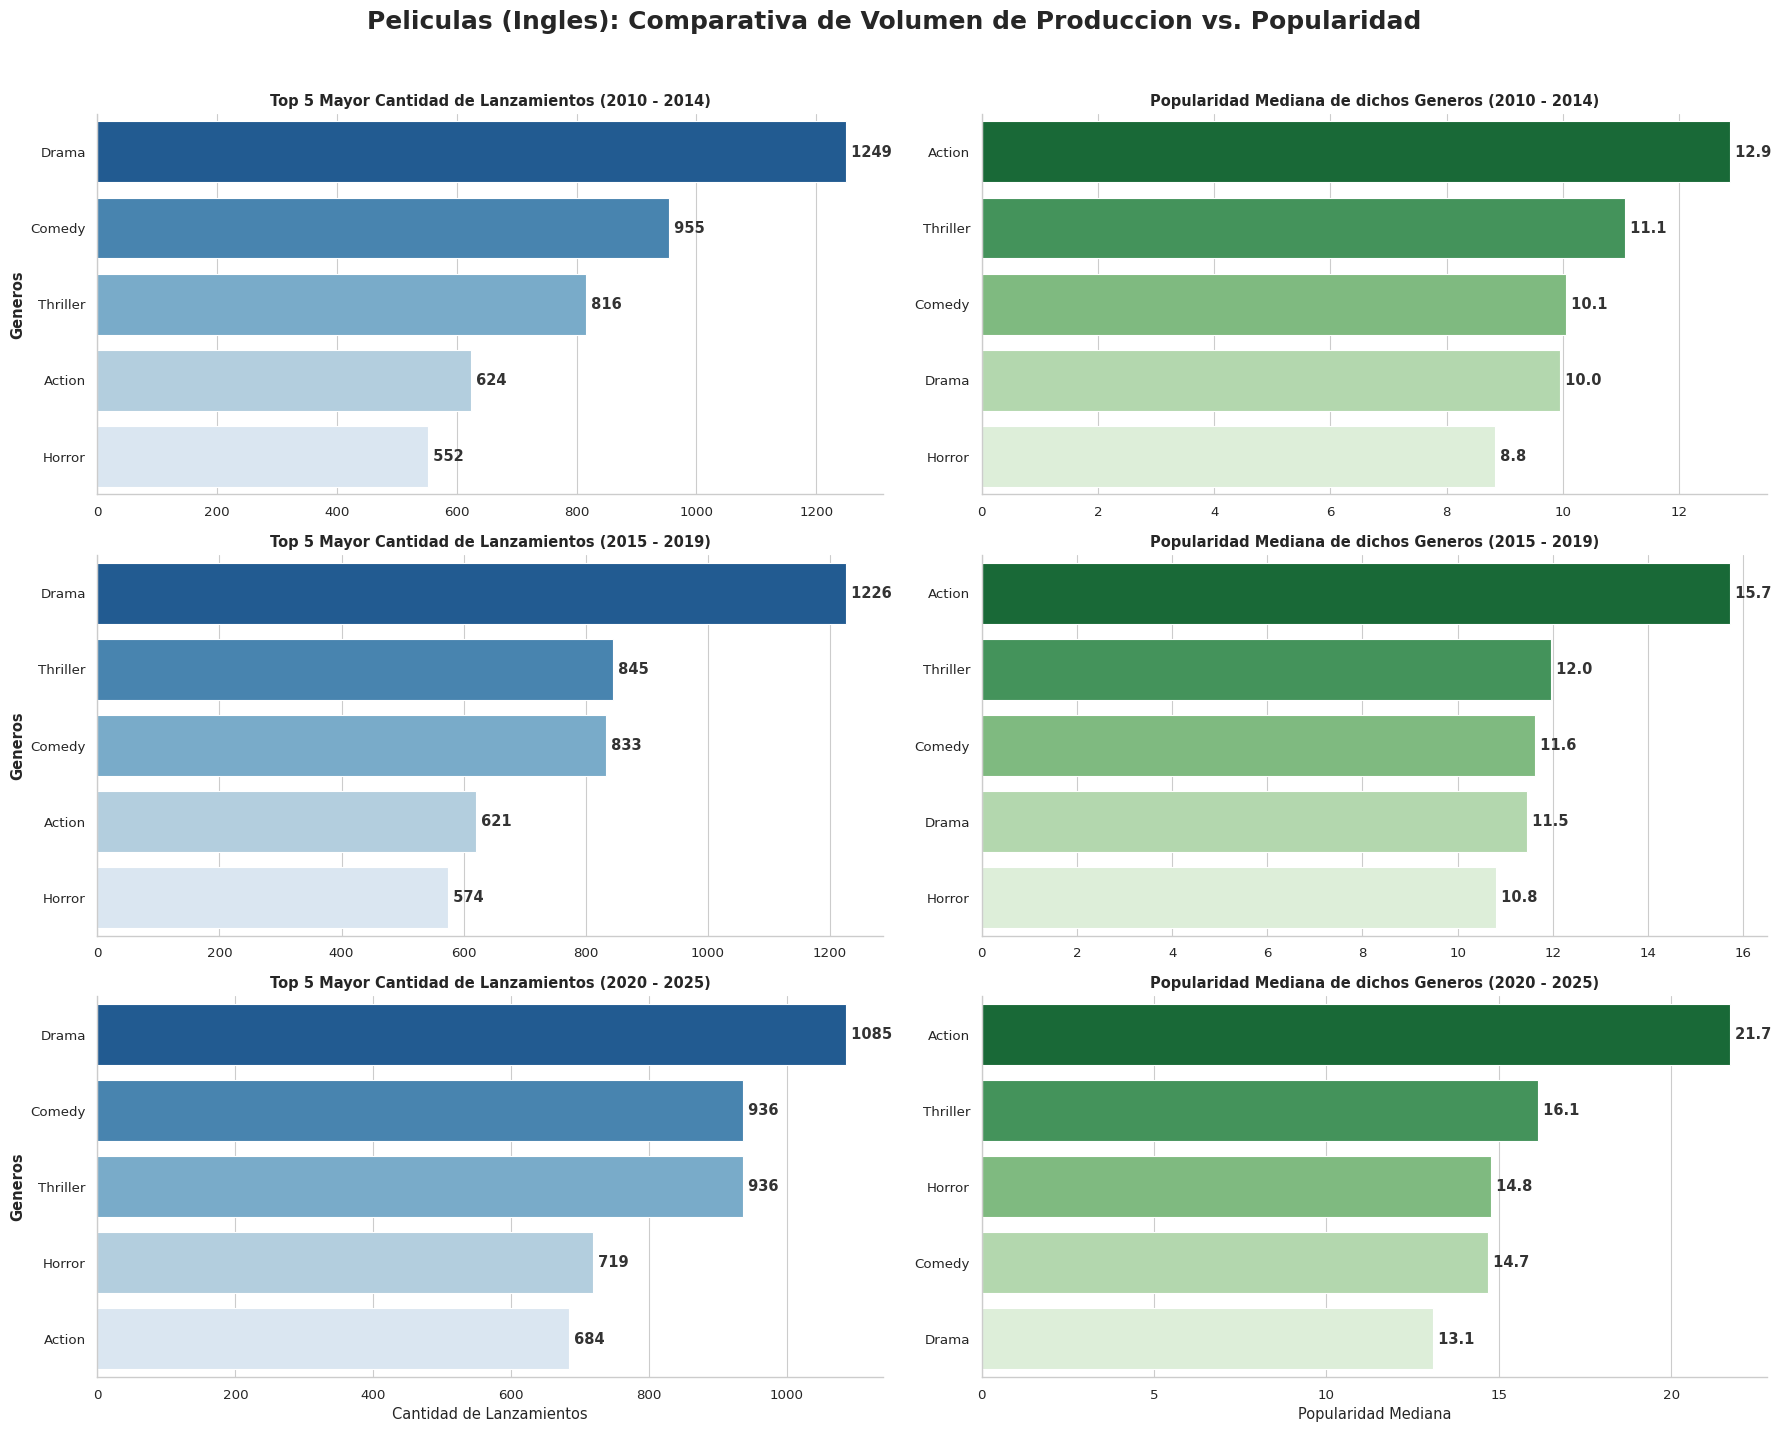

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuracion visual para reducir la carga cognitiva
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

def preparar_datos_rangos(df):
    """Limpia, filtra por idioma ingles, filtra años y separa generos."""
    df_clean = df.dropna(subset=['release_year', 'genres', 'language', 'popularity']).copy()

    # Filtro de idioma ingles
    df_clean['language'] = df_clean['language'].astype(str).str.strip().str.lower()
    df_clean = df_clean[df_clean['language'].isin(['en', 'english'])]

    # Limpieza de año y creacion de rangos
    df_clean['year_clean'] = pd.to_numeric(df_clean['release_year'], errors='coerce')
    df_clean = df_clean[(df_clean['year_clean'] >= 2010) & (df_clean['year_clean'] <= 2025)]

    df_clean['Rango_Anos'] = pd.cut(
        df_clean['year_clean'],
        bins=[2009, 2014, 2019, 2025],
        labels=['2010 - 2014', '2015 - 2019', '2020 - 2025']
    )
    df_clean = df_clean.dropna(subset=['Rango_Anos'])

    # Separacion de multiples generos
    df_clean['genres'] = df_clean['genres'].astype(str).str.split(',')
    df_exp = df_clean.explode('genres')
    df_exp['genres'] = df_exp['genres'].str.strip()

    return df_exp

def generar_panel_comparativo(df_procesado, titulo_principal, color_cant, color_pop):
    """Genera una figura de 3x2 contrastando cantidad vs popularidad por rango de años."""
    rangos = ['2010 - 2014', '2015 - 2019', '2020 - 2025']
    fig, axes = plt.subplots(3, 2, figsize=(18, 14))
    fig.suptitle(titulo_principal, fontsize=18, weight='bold', y=1.02)

    for i, rango in enumerate(rangos):
        df_rango = df_procesado[df_procesado['Rango_Anos'] == rango]

        if not df_rango.empty:
            # 1. Calcular el Top 5 por Cantidad de Lanzamientos
            top5_cant = df_rango['genres'].value_counts().head(5).reset_index()
            top5_cant.columns = ['genres', 'Cantidad']

            # 2. Filtrar para calcular la Popularidad solo de esos 5 generos especificos
            generos_top = top5_cant['genres'].tolist()
            df_top5_pop = df_rango[df_rango['genres'].isin(generos_top)]

            top5_pop = df_top5_pop.groupby('genres')['popularity'].median().reset_index()
            top5_pop = top5_pop.sort_values('popularity', ascending=False)

            # Grafico Izquierdo: Cantidad
            sns.barplot(data=top5_cant, x='Cantidad', y='genres', ax=axes[i, 0], palette=color_cant)
            axes[i, 0].set_title(f'Top 5 Mayor Cantidad de Lanzamientos ({rango})', weight='bold')
            axes[i, 0].set_ylabel('Generos', weight='bold')
            axes[i, 0].set_xlabel('Cantidad de Lanzamientos' if i == 2 else '')

            # Agregar etiquetas de datos (Cantidad)
            for index, value in enumerate(top5_cant['Cantidad']):
                axes[i, 0].text(value, index, f' {int(value)}', va='center', weight='bold', color='#333333')

            # Grafico Derecho: Popularidad Mediana
            sns.barplot(data=top5_pop, x='popularity', y='genres', ax=axes[i, 1], palette=color_pop)
            axes[i, 1].set_title(f'Popularidad Mediana de dichos Generos ({rango})', weight='bold')
            axes[i, 1].set_ylabel('')
            axes[i, 1].set_xlabel('Popularidad Mediana' if i == 2 else '')

            # Agregar etiquetas de datos (Popularidad)
            for index, value in enumerate(top5_pop['popularity']):
                axes[i, 1].text(value, index, f' {value:.1f}', va='center', weight='bold', color='#333333')

        else:
            axes[i, 0].set_visible(False)
            axes[i, 1].set_visible(False)

    plt.tight_layout()
    plt.show()

# ==========================================
# EJECUCION PARA PELICULAS
# ==========================================
df_peliculas_procesado = preparar_datos_rangos(df_peliculas)
generar_panel_comparativo(
    df_procesado=df_peliculas_procesado,
    titulo_principal='Peliculas (Ingles): Comparativa de Volumen de Produccion vs. Popularidad',
    color_cant='Blues_r',
    color_pop='Greens_r'
)



/tmp/ipykernel_3449/1501978410.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top5_cant, x='Cantidad', y='genres', ax=axes[i, 0], palette=color_cant)
/tmp/ipykernel_3449/1501978410.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top5_pop, x='popularity', y='genres', ax=axes[i, 1], palette=color_pop)
/tmp/ipykernel_3449/1501978410.py:58: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top5_cant, x='Cantidad', y='genres', ax=axes[i, 0], palette=color_cant)
/tmp/ipykernel_3449/1501978410.py:68: FutureWarning: 

Passing `

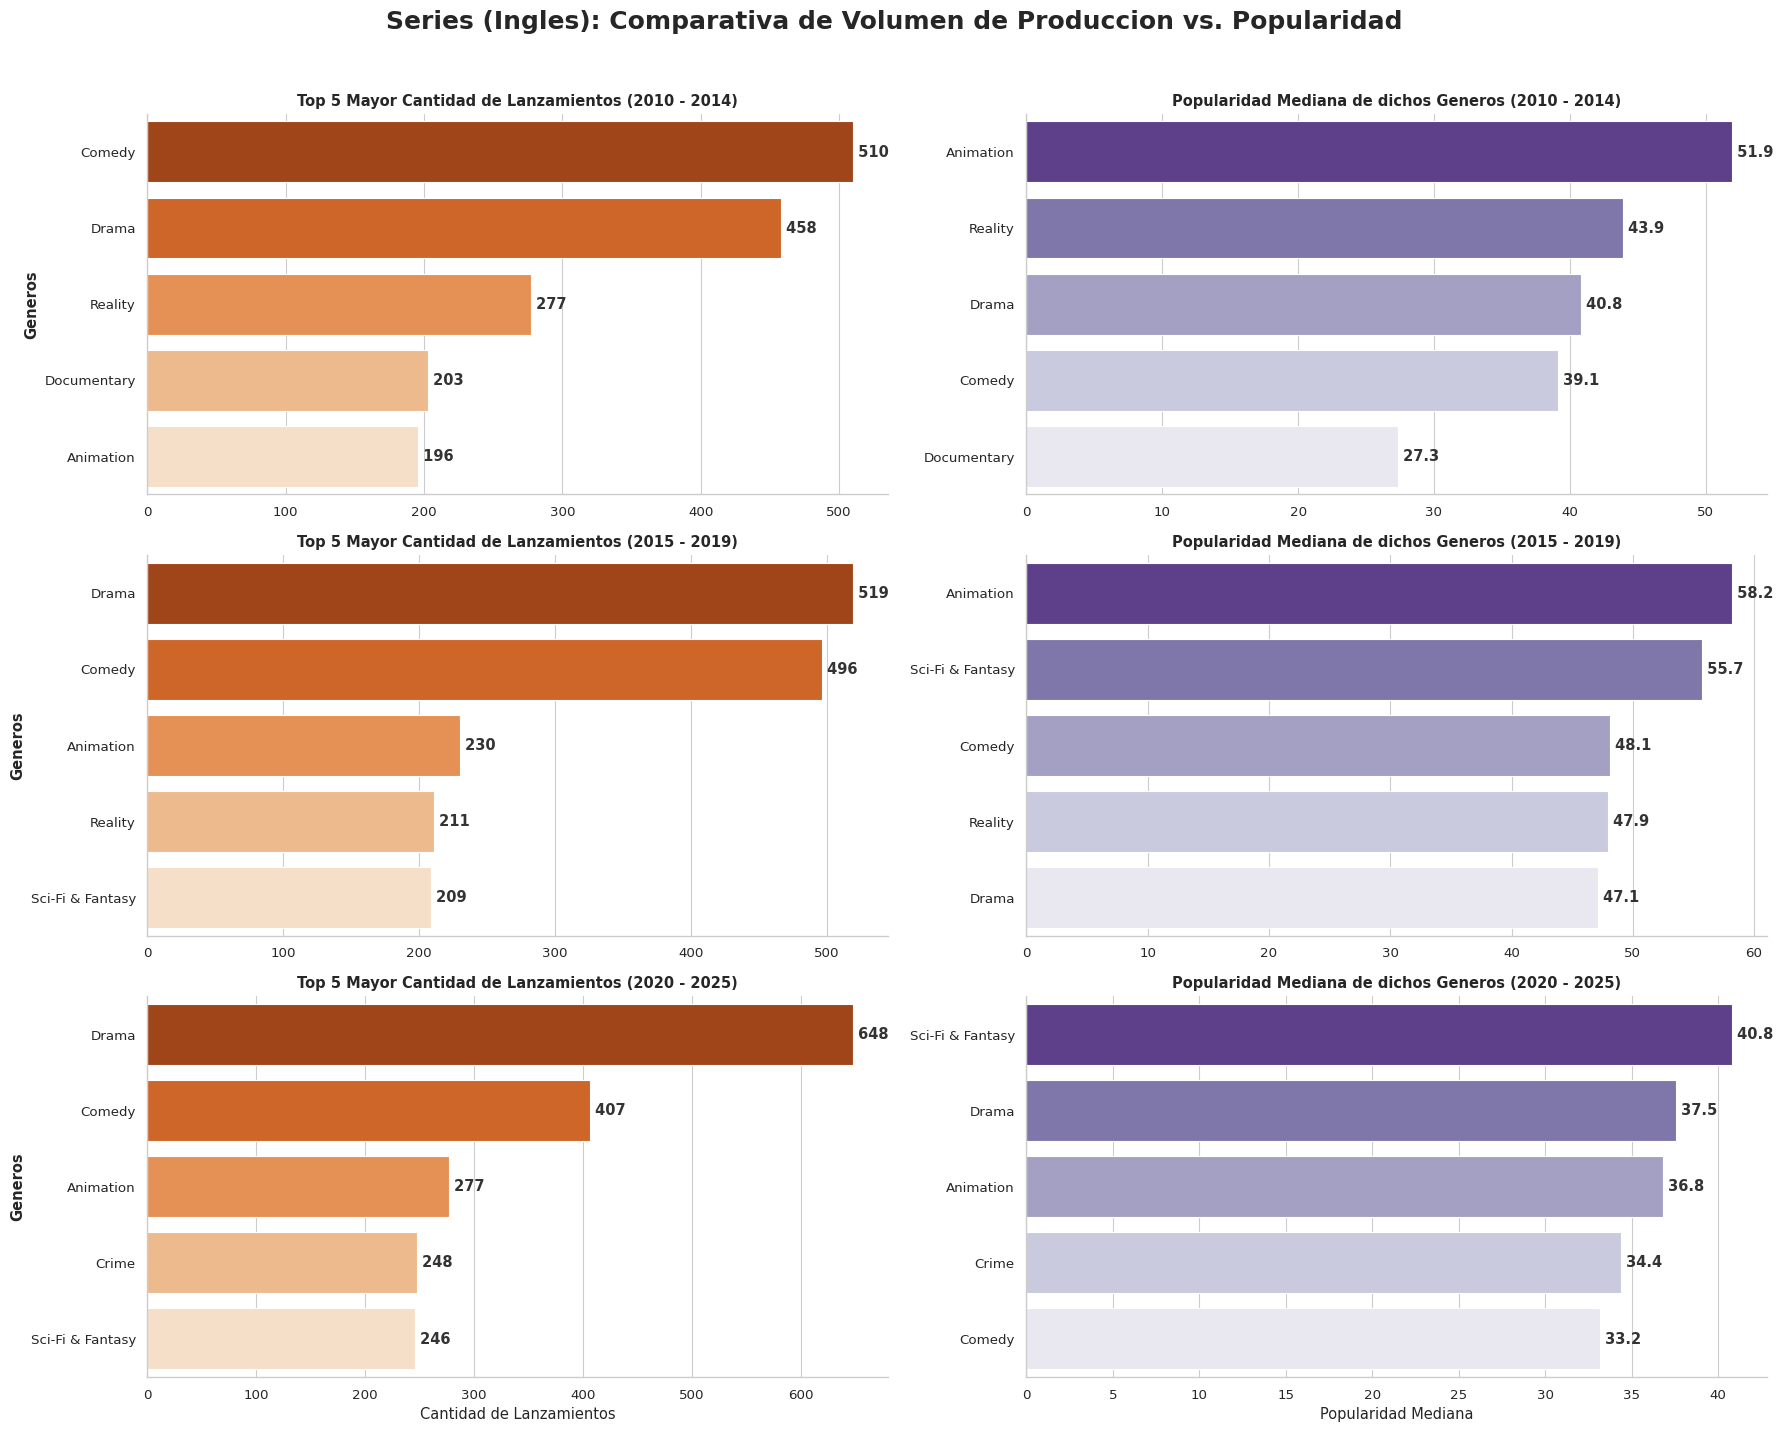

In [ ]:
# ==========================================
# EJECUCION PARA SERIES
# ==========================================
df_series_procesado = preparar_datos_rangos(df_series)
generar_panel_comparativo(
    df_procesado=df_series_procesado,
    titulo_principal='Series (Ingles): Comparativa de Volumen de Produccion vs. Popularidad',
    color_cant='Oranges_r',
    color_pop='Purples_r'
)

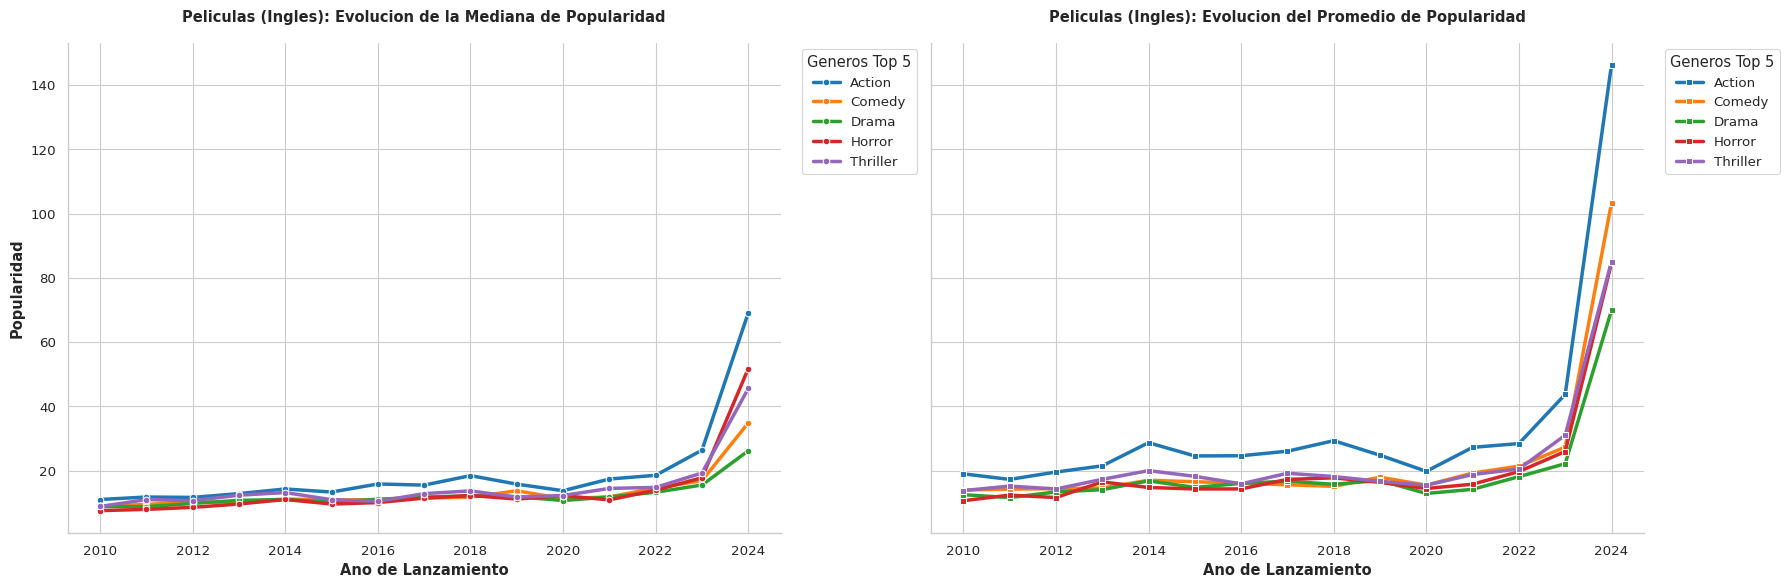

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# 1. Preparacion de datos (Peliculas en Ingles)
df_p = df_peliculas.dropna(subset=['release_year', 'genres', 'language', 'popularity']).copy()
df_p['language'] = df_p['language'].astype(str).str.strip().str.lower()
df_p = df_p[df_p['language'].isin(['en', 'english'])]

df_p['year_clean'] = pd.to_numeric(df_p['release_year'], errors='coerce')
df_p = df_p[(df_p['year_clean'] >= 2010) & (df_p['year_clean'] <= 2024)]

df_p['genres'] = df_p['genres'].astype(str).str.split(',')
df_p_exp = df_p.explode('genres')
df_p_exp['genres'] = df_p_exp['genres'].str.strip()

# Top 5 historico por cantidad de apariciones
top5_generos_p = df_p_exp['genres'].value_counts().head(5).index.tolist()
df_p_top5 = df_p_exp[df_p_exp['genres'].isin(top5_generos_p)]

# Calcular mediana y promedio anual por genero
stats_p = df_p_top5.groupby(['year_clean', 'genres'])['popularity'].agg(
    Mediana='median',
    Promedio='mean'
).reset_index()

# 2. Creacion de la figura dual (Mediana vs Promedio)
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

sns.lineplot(data=stats_p, x='year_clean', y='Mediana', hue='genres', marker='o', linewidth=2.5, ax=axes[0], palette='tab10')
axes[0].set_title('Peliculas (Ingles): Evolucion de la Mediana de Popularidad', weight='bold', pad=15)
axes[0].set_xlabel('Ano de Lanzamiento', weight='bold')
axes[0].set_ylabel('Popularidad', weight='bold')
axes[0].legend(title='Generos Top 5', bbox_to_anchor=(1.02, 1), loc='upper left')

sns.lineplot(data=stats_p, x='year_clean', y='Promedio', hue='genres', marker='s', linewidth=2.5, ax=axes[1], palette='tab10')
axes[1].set_title('Peliculas (Ingles): Evolucion del Promedio de Popularidad', weight='bold', pad=15)
axes[1].set_xlabel('Ano de Lanzamiento', weight='bold')
axes[1].set_ylabel('')
axes[1].legend(title='Generos Top 5', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

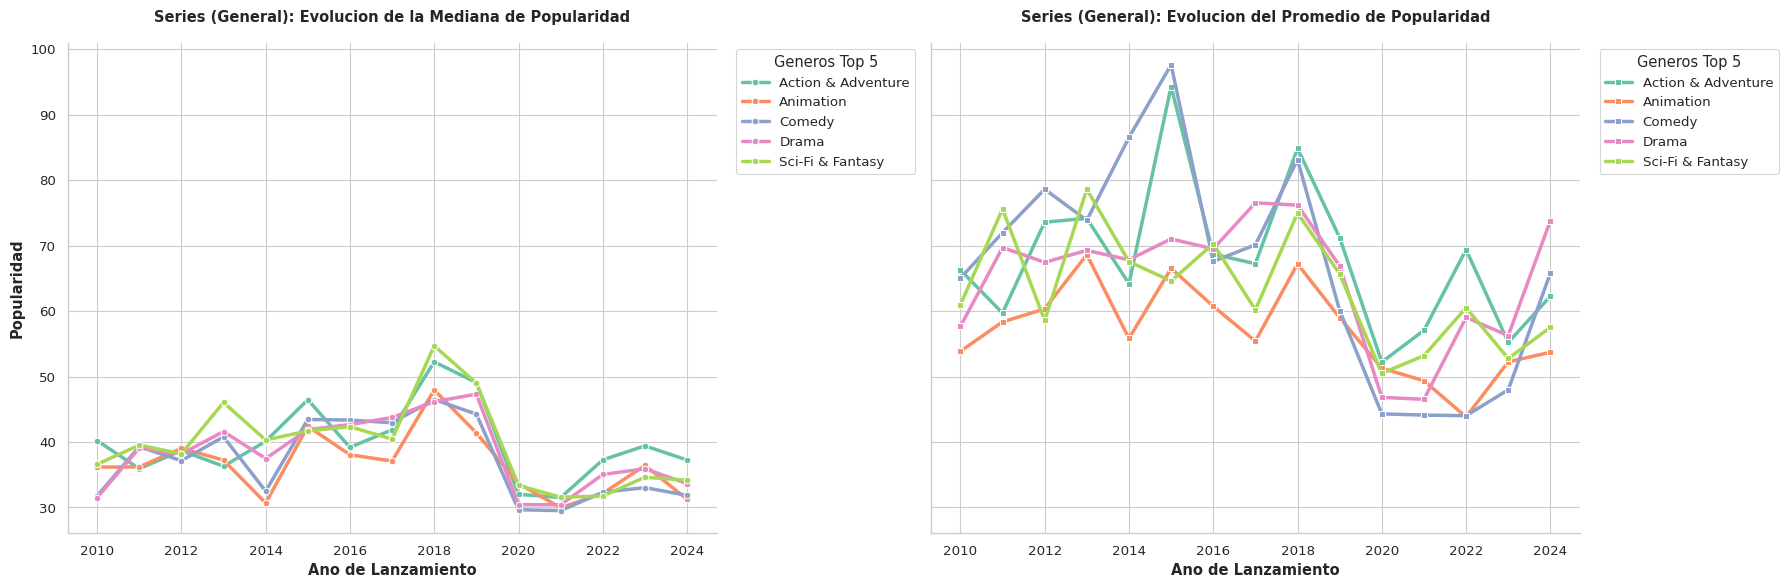

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# 1. Preparacion de datos (Series en General)
df_s = df_series.dropna(subset=['release_year', 'genres', 'popularity']).copy()

df_s['year_clean'] = pd.to_numeric(df_s['release_year'], errors='coerce')
df_s = df_s[(df_s['year_clean'] >= 2010) & (df_s['year_clean'] <= 2024)]

df_s['genres'] = df_s['genres'].astype(str).str.split(',')
df_s_exp = df_s.explode('genres')
df_s_exp['genres'] = df_s_exp['genres'].str.strip()

# Top 5 historico por cantidad de apariciones en general
top5_generos_s = df_s_exp['genres'].value_counts().head(5).index.tolist()
df_s_top5 = df_s_exp[df_s_exp['genres'].isin(top5_generos_s)]

# Calcular mediana y promedio anual por genero
stats_s = df_s_top5.groupby(['year_clean', 'genres'])['popularity'].agg(
    Mediana='median',
    Promedio='mean'
).reset_index()

# 2. Creacion de la figura dual (Mediana vs Promedio)
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

sns.lineplot(data=stats_s, x='year_clean', y='Mediana', hue='genres', marker='o', linewidth=2.5, ax=axes[0], palette='Set2')
axes[0].set_title('Series (General): Evolucion de la Mediana de Popularidad', weight='bold', pad=15)
axes[0].set_xlabel('Ano de Lanzamiento', weight='bold')
axes[0].set_ylabel('Popularidad', weight='bold')
axes[0].legend(title='Generos Top 5', bbox_to_anchor=(1.02, 1), loc='upper left')

sns.lineplot(data=stats_s, x='year_clean', y='Promedio', hue='genres', marker='s', linewidth=2.5, ax=axes[1], palette='Set2')
axes[1].set_title('Series (General): Evolucion del Promedio de Popularidad', weight='bold', pad=15)
axes[1].set_xlabel('Ano de Lanzamiento', weight='bold')
axes[1].set_ylabel('')
axes[1].legend(title='Generos Top 5', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [ ]:
# Verificacion rapida de registros y popularidad por año
verificacion = df_peliculas[df_peliculas['release_year'].isin([2024, 2025])].groupby('release_year').agg(
    Total_Registros=('popularity', 'count'),
    Popularidad_Media=('popularity', 'mean'),
    Popularidad_Mediana=('popularity', 'median')
).reset_index()

print(verificacion)

   release_year  Total_Registros  Popularidad_Media  Popularidad_Mediana
0          2024             1000          74.043703              27.6770
1          2025             1000          33.768222               8.6455


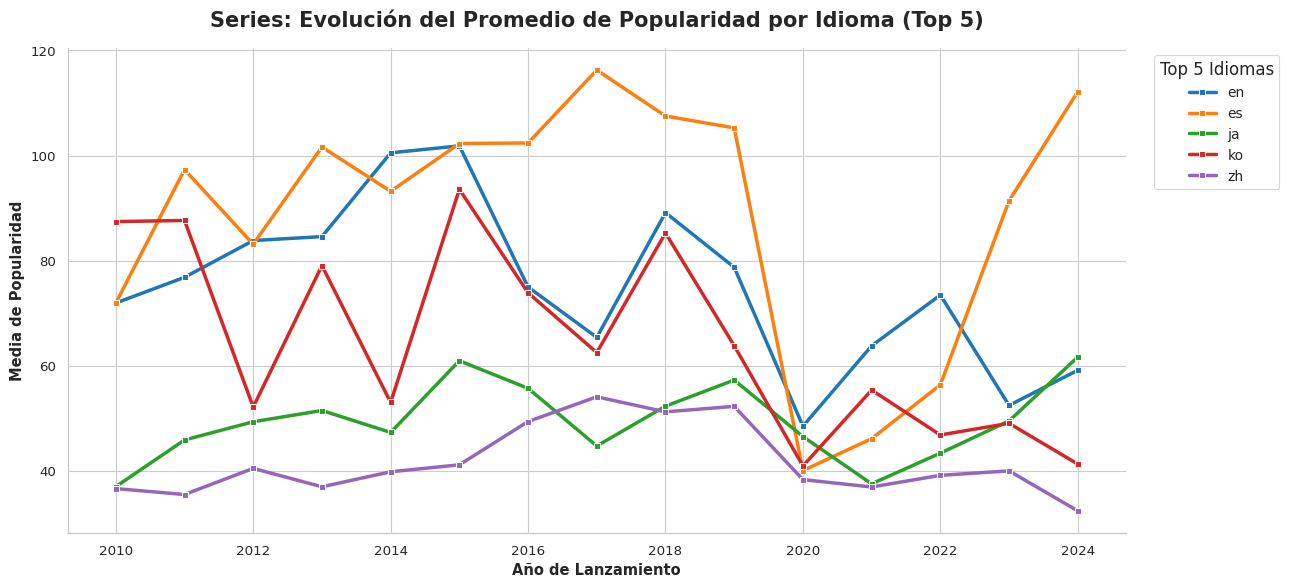

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual alineada al estilo anterior
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# 1. Preparación de datos (Series - Análisis por Idioma)
df_s_lang = df_series.dropna(subset=['release_year', 'language', 'popularity']).copy()

df_s_lang['year_clean'] = pd.to_numeric(df_s_lang['release_year'], errors='coerce')
df_s_lang = df_s_lang[(df_s_lang['year_clean'] >= 2010) & (df_s_lang['year_clean'] <= 2024)]

# Limpieza básica del campo de idioma (minúsculas y sin espacios)
df_s_lang['language'] = df_s_lang['language'].astype(str).str.strip().str.lower()

# 2. Obtener el Top 5 histórico de idiomas con más series producidas
top5_idiomas = df_s_lang['language'].value_counts().head(5).index.tolist()
df_s_top5_lang = df_s_lang[df_s_lang['language'].isin(top5_idiomas)]

# 3. Calcular SOLO el promedio (media) anual de popularidad por idioma
stats_idiomas = df_s_top5_lang.groupby(['year_clean', 'language'])['popularity'].mean().reset_index(name='Promedio')

# 4. Creación de la figura única (Promedio por Idioma)
plt.figure(figsize=(13, 6))

sns.lineplot(
    data=stats_idiomas,
    x='year_clean',
    y='Promedio',
    hue='language',
    marker='s',
    linewidth=2.5,
    palette='tab10'
)

plt.title('Series: Evolución del Promedio de Popularidad por Idioma (Top 5)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Año de Lanzamiento', weight='bold')
plt.ylabel('Media de Popularidad', weight='bold')

plt.legend(title='Top 5 Idiomas', title_fontsize='12', fontsize='10', bbox_to_anchor=(1.02, 1), loc='upper left')

# Opcional: Asegurar que el eje X muestre números enteros para los años
import numpy as np
plt.xticks(np.arange(2010, 2025, 2))

plt.tight_layout()
plt.show()

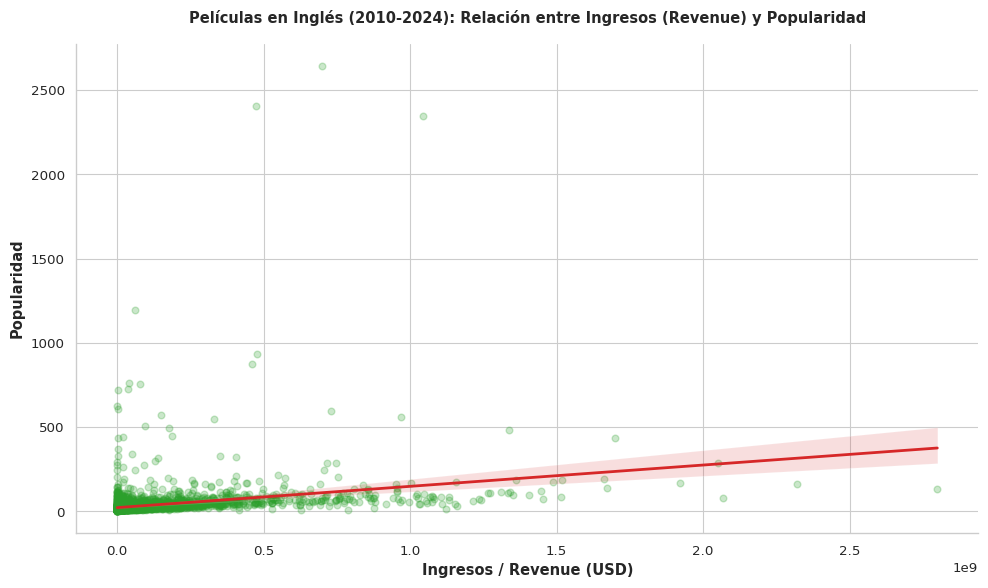

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Preparación de datos para películas (asegurando revenue, popularity, language y year)
df_p_rev = df_peliculas.dropna(subset=['popularity', 'revenue', 'release_year', 'language']).copy()
df_p_rev['language'] = df_p_rev['language'].astype(str).str.strip().str.lower()
df_p_rev = df_p_rev[df_p_rev['language'].isin(['en', 'english'])]

df_p_rev['year_clean'] = pd.to_numeric(df_p_rev['release_year'], errors='coerce')

# Filtros: Años de 2010 a 2024, y eliminar ingresos o popularidad en 0 para limpiar el ruido
df_p_rev = df_p_rev[
    (df_p_rev['year_clean'] >= 2010) &
    (df_p_rev['year_clean'] <= 2024) &
    (df_p_rev['revenue'] > 0) &
    (df_p_rev['popularity'] > 0)
]

plt.figure(figsize=(10, 6))

# Gráfico de dispersión con línea de tendencia
sns.regplot(
    data=df_p_rev,
    x='revenue',
    y='popularity',
    scatter_kws={'alpha': 0.25, 'color': '#2ca02c'},
    line_kws={'color': '#d62728', 'linewidth': 2}
)

# Formatear el eje X para que los ingresos se lean en millones (opcional pero ayuda a la vista)
plt.title('Películas en Inglés (2010-2024): Relación entre Ingresos (Revenue) y Popularidad', weight='bold', pad=15)
plt.xlabel('Ingresos / Revenue (USD)', weight='bold')
plt.ylabel('Popularidad', weight='bold')

plt.tight_layout()
plt.show()

#Analisis por interaccion


Luego de hacer un analisis de como se comportaba la popularidad, ahora queremos ver como se comportan los usuarios, cuales son las series con las que más interactuan y encontrar informacion relevante

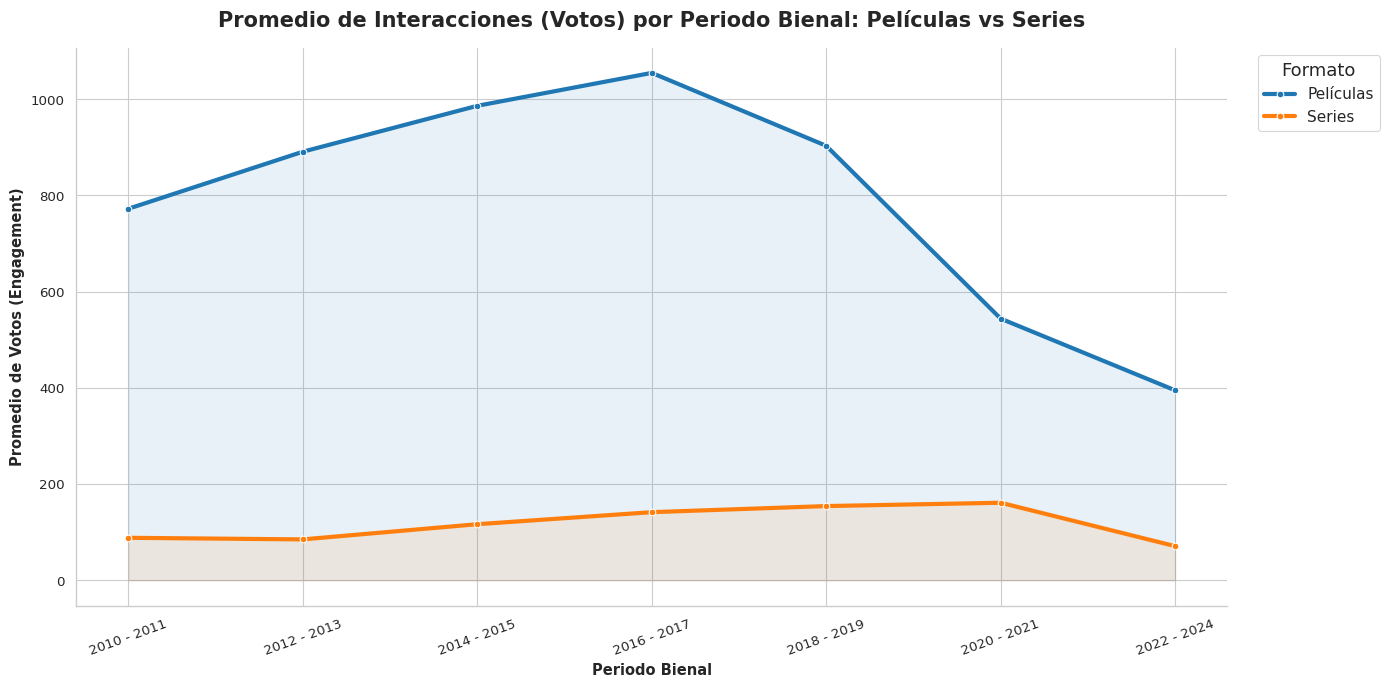

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Definir rangos bienales
bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

# --- 1. Preparar datos de Películas ---
df_p = df_peliculas.dropna(subset=['release_year', 'vote_count']).copy()
df_p['year_clean'] = pd.to_numeric(df_p['release_year'], errors='coerce')
df_p = df_p[(df_p['year_clean'] >= 2010) & (df_p['year_clean'] <= 2024)]
df_p['Rango_Anos'] = pd.cut(df_p['year_clean'], bins=bins, labels=labels)

# Calcular promedio de votos para películas
media_votos_p = df_p.groupby('Rango_Anos', observed=False)['vote_count'].mean().reset_index()
media_votos_p['Formato'] = 'Películas'

# --- 2. Preparar datos de Series ---
df_s = df_series.dropna(subset=['release_year', 'vote_count']).copy()
df_s['year_clean'] = pd.to_numeric(df_s['release_year'], errors='coerce')
df_s = df_s[(df_s['year_clean'] >= 2010) & (df_s['year_clean'] <= 2024)]
df_s['Rango_Anos'] = pd.cut(df_s['year_clean'], bins=bins, labels=labels)

# Calcular promedio de votos para series
media_votos_s = df_s.groupby('Rango_Anos', observed=False)['vote_count'].mean().reset_index()
media_votos_s['Formato'] = 'Series'

# --- 3. Unir ambos datasets para la comparativa ---
df_comparativo = pd.concat([media_votos_p, media_votos_s], ignore_index=True)

# --- 4. Generación del gráfico ---
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=df_comparativo,
    x='Rango_Anos',
    y='vote_count',
    hue='Formato',
    marker='o',
    linewidth=3,
    palette=['#1f77b4', '#ff7f0e'] # Azul para películas, Naranja para series
)

# Rellenar sutilmente el área bajo las líneas para dar un toque más profesional
plt.fill_between(
    media_votos_p['Rango_Anos'].astype(str),
    media_votos_p['vote_count'],
    alpha=0.1, color='#1f77b4'
)
plt.fill_between(
    media_votos_s['Rango_Anos'].astype(str),
    media_votos_s['vote_count'],
    alpha=0.1, color='#ff7f0e'
)

plt.title('Promedio de Interacciones (Votos) por Periodo Bienal: Películas vs Series', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Promedio de Votos (Engagement)', weight='bold')

plt.legend(title='Formato', title_fontsize='13', fontsize='11', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

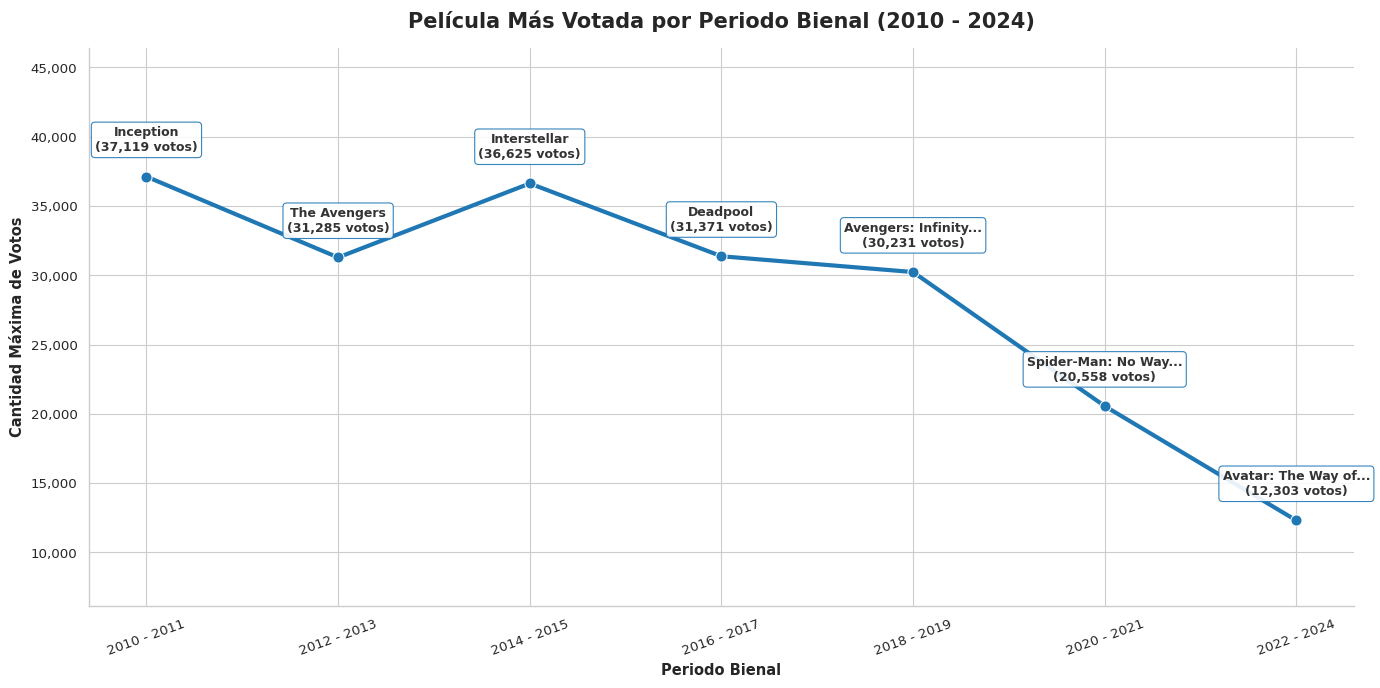

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

# Preparar datos
df_p = df_peliculas.dropna(subset=['release_year', 'title', 'vote_count']).copy()
df_p['year_clean'] = pd.to_numeric(df_p['release_year'], errors='coerce')
df_p = df_p[(df_p['year_clean'] >= 2010) & (df_p['year_clean'] <= 2024)]
df_p['Rango_Anos'] = pd.cut(df_p['year_clean'], bins=bins, labels=labels)

# Extraer la película con más votos por cada periodo
top_pelis_list = []
for etiqueta in labels:
    subset = df_p[df_p['Rango_Anos'] == etiqueta]
    if not subset.empty:
        top_idx = subset['vote_count'].idxmax()
        top_pelis_list.append(subset.loc[top_idx])

df_top_p = pd.DataFrame(top_pelis_list)

# Gráfico
plt.figure(figsize=(14, 7))
sns.lineplot(data=df_top_p, x='Rango_Anos', y='vote_count', marker='o', markersize=8, linewidth=3, color='#1f77b4')

# Etiquetas sobre los puntos
for i, row in df_top_p.reset_index(drop=True).iterrows():
    titulo = str(row['title'])
    titulo_corto = (titulo[:18] + '...') if len(titulo) > 18 else titulo
    votos = row['vote_count']

    plt.text(
        i,
        votos + (df_top_p['vote_count'].max() * 0.05),
        f"{titulo_corto}\n({votos:,.0f} votos)",
        ha='center',
        color='#333333',
        weight='bold',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#1f77b4', alpha=0.9)
    )

# Ajustar escala Y para que las etiquetas no se corten
plt.ylim(df_top_p['vote_count'].min() * 0.5, df_top_p['vote_count'].max() * 1.25)
plt.gca().get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.title('Película Más Votada por Periodo Bienal (2010 - 2024)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Cantidad Máxima de Votos', weight='bold')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

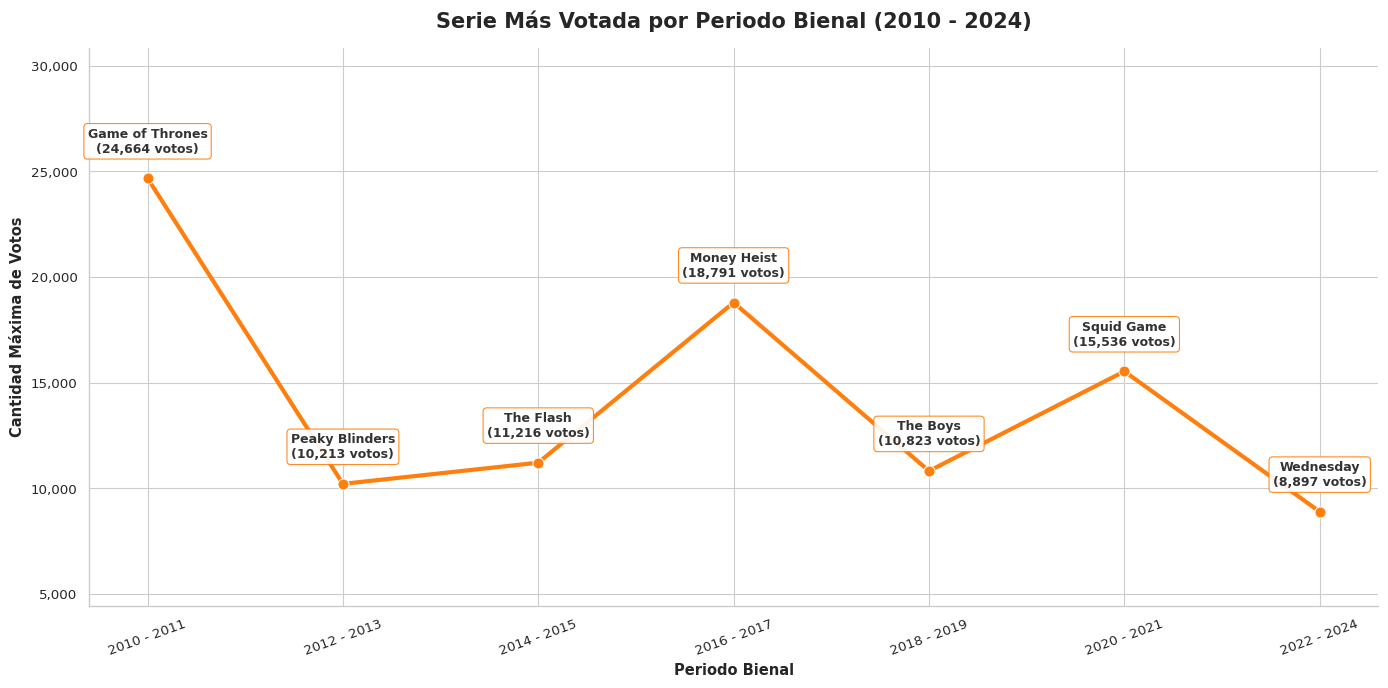

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

# Preparar datos
df_s = df_series.dropna(subset=['release_year', 'title', 'vote_count']).copy()
df_s['year_clean'] = pd.to_numeric(df_s['release_year'], errors='coerce')
df_s = df_s[(df_s['year_clean'] >= 2010) & (df_s['year_clean'] <= 2024)]
df_s['Rango_Anos'] = pd.cut(df_s['year_clean'], bins=bins, labels=labels)

# Extraer la serie con más votos por cada periodo
top_series_list = []
for etiqueta in labels:
    subset = df_s[df_s['Rango_Anos'] == etiqueta]
    if not subset.empty:
        top_idx = subset['vote_count'].idxmax()
        top_series_list.append(subset.loc[top_idx])

df_top_s = pd.DataFrame(top_series_list)

# Gráfico
plt.figure(figsize=(14, 7))
sns.lineplot(data=df_top_s, x='Rango_Anos', y='vote_count', marker='o', markersize=8, linewidth=3, color='#ff7f0e')

# Etiquetas sobre los puntos
for i, row in df_top_s.reset_index(drop=True).iterrows():
    titulo = str(row['title'])
    titulo_corto = (titulo[:18] + '...') if len(titulo) > 18 else titulo
    votos = row['vote_count']

    plt.text(
        i,
        votos + (df_top_s['vote_count'].max() * 0.05),
        f"{titulo_corto}\n({votos:,.0f} votos)",
        ha='center',
        color='#333333',
        weight='bold',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#ff7f0e', alpha=0.9)
    )

# Ajustar escala Y
plt.ylim(df_top_s['vote_count'].min() * 0.5, df_top_s['vote_count'].max() * 1.25)
plt.gca().get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.title('Serie Más Votada por Periodo Bienal (2010 - 2024)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Cantidad Máxima de Votos', weight='bold')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

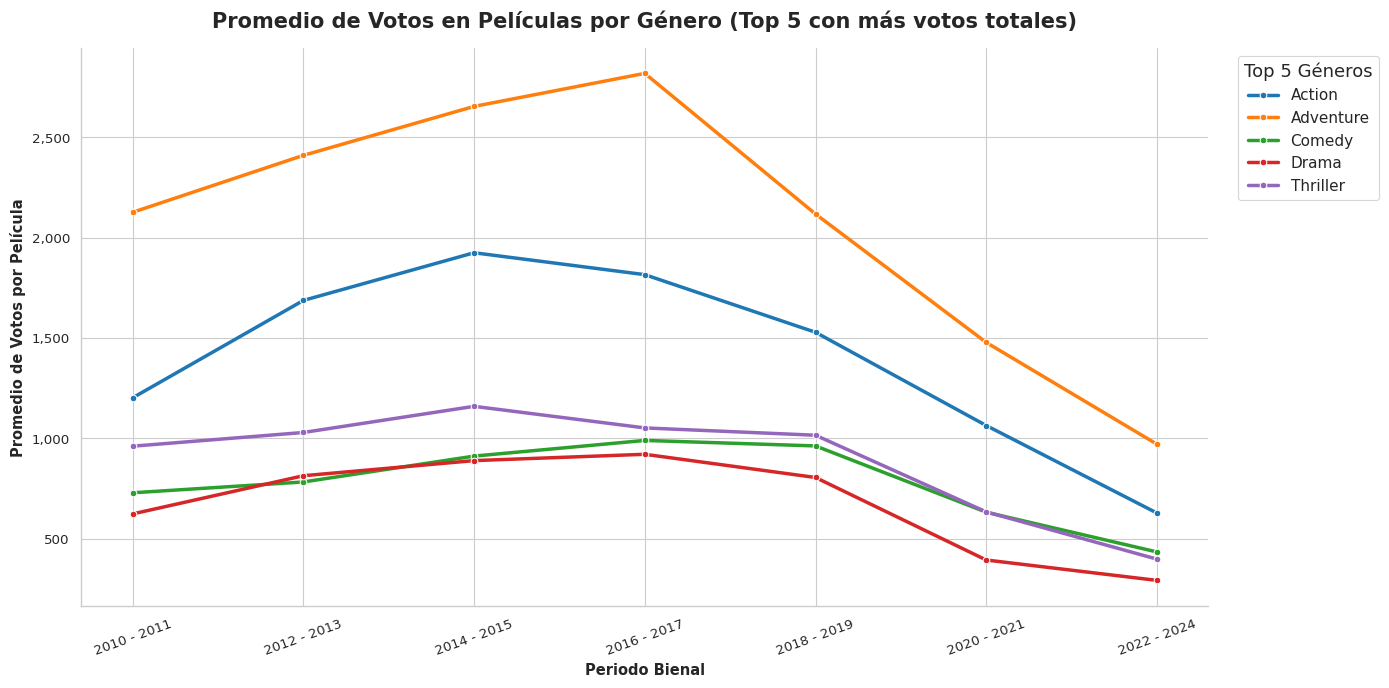

Top 5 géneros con más votos totales en películas: ['Drama', 'Action', 'Adventure', 'Comedy', 'Thriller']


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

# 1. Preparar datos y filtrar años
df_p = df_peliculas.dropna(subset=['release_year', 'genres', 'vote_count']).copy()
df_p['year_clean'] = pd.to_numeric(df_p['release_year'], errors='coerce')
df_p = df_p[(df_p['year_clean'] >= 2010) & (df_p['year_clean'] <= 2024)]
df_p['Rango_Anos'] = pd.cut(df_p['year_clean'], bins=bins, labels=labels)

# 2. Separar películas con múltiples géneros
df_p_exp = df_p.copy()
df_p_exp['genres_list'] = df_p_exp['genres'].astype(str).str.split(',')
df_p_exp = df_p_exp.explode('genres_list')
df_p_exp['genres_list'] = df_p_exp['genres_list'].str.strip()

# 3. Identificar el Top 5 de géneros con MAYOR CANTIDAD TOTAL de votos
top_5_generos_p = df_p_exp.groupby('genres_list')['vote_count'].sum().nlargest(5).index.tolist()
df_top_p = df_p_exp[df_p_exp['genres_list'].isin(top_5_generos_p)].copy()

# 4. Calcular el PROMEDIO de votos por periodo para ese Top 5
media_votos_p = df_top_p.groupby(['Rango_Anos', 'genres_list'], observed=False)['vote_count'].mean().reset_index(name='Promedio_Votos')

# 5. Gráfico
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=media_votos_p,
    x='Rango_Anos',
    y='Promedio_Votos',
    hue='genres_list',
    marker='o',
    linewidth=2.5,
    palette='tab10'
)

# Formatear el eje Y para separar miles con comas
plt.gca().get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.title('Promedio de Votos en Películas por Género (Top 5 con más votos totales)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Promedio de Votos por Película', weight='bold')
plt.legend(title='Top 5 Géneros', title_fontsize='13', fontsize='11', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("Top 5 géneros con más votos totales en películas:", top_5_generos_p)

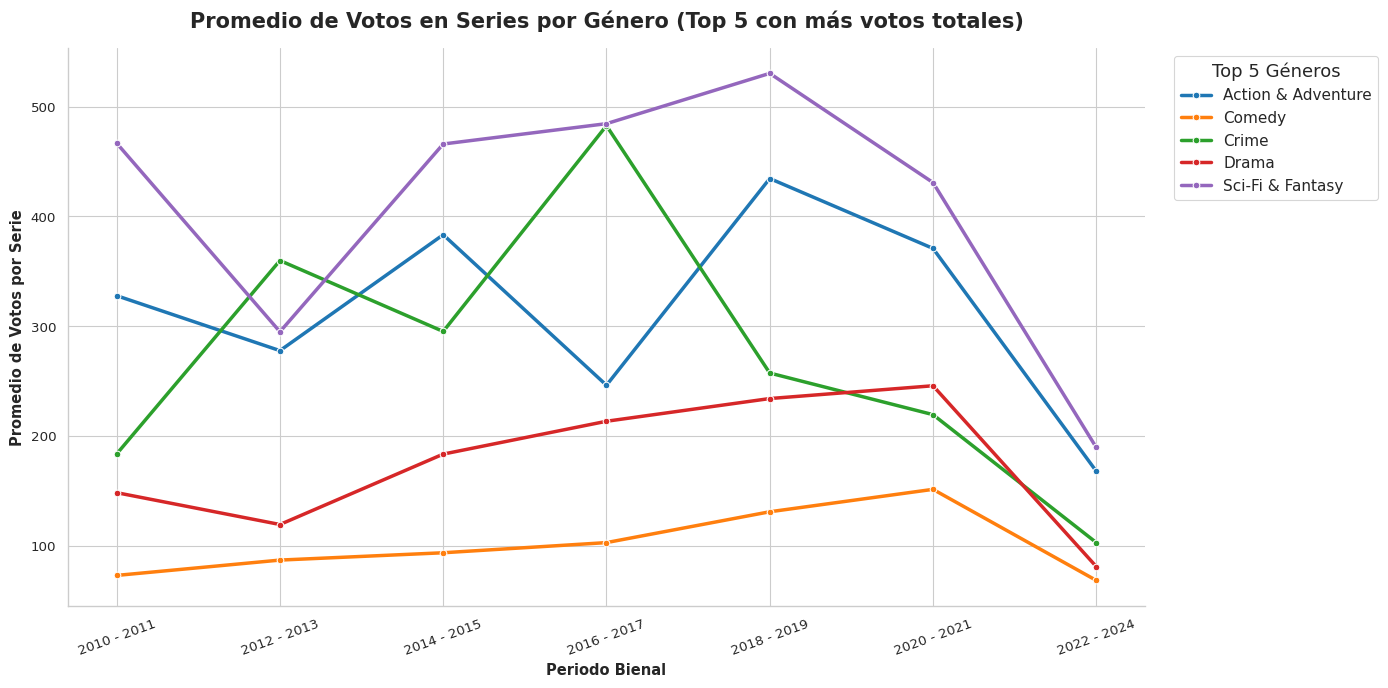

Top 5 géneros con más votos totales en series: ['Drama', 'Sci-Fi & Fantasy', 'Action & Adventure', 'Comedy', 'Crime']


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

bins = [2009, 2011, 2013, 2015, 2017, 2019, 2021, 2024]
labels = ['2010 - 2011', '2012 - 2013', '2014 - 2015', '2016 - 2017', '2018 - 2019', '2020 - 2021', '2022 - 2024']

# 1. Preparar datos y filtrar años
df_s = df_series.dropna(subset=['release_year', 'genres', 'vote_count']).copy()
df_s['year_clean'] = pd.to_numeric(df_s['release_year'], errors='coerce')
df_s = df_s[(df_s['year_clean'] >= 2010) & (df_s['year_clean'] <= 2024)]
df_s['Rango_Anos'] = pd.cut(df_s['year_clean'], bins=bins, labels=labels)

# 2. Separar series con múltiples géneros
df_s_exp = df_s.copy()
df_s_exp['genres_list'] = df_s_exp['genres'].astype(str).str.split(',')
df_s_exp = df_s_exp.explode('genres_list')
df_s_exp['genres_list'] = df_s_exp['genres_list'].str.strip()

# 3. Identificar el Top 5 de géneros con MAYOR CANTIDAD TOTAL de votos
top_5_generos_s = df_s_exp.groupby('genres_list')['vote_count'].sum().nlargest(5).index.tolist()
df_top_s = df_s_exp[df_s_exp['genres_list'].isin(top_5_generos_s)].copy()

# 4. Calcular el PROMEDIO de votos por periodo para ese Top 5
media_votos_s = df_top_s.groupby(['Rango_Anos', 'genres_list'], observed=False)['vote_count'].mean().reset_index(name='Promedio_Votos')

# 5. Gráfico
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=media_votos_s,
    x='Rango_Anos',
    y='Promedio_Votos',
    hue='genres_list',
    marker='o',
    linewidth=2.5,
    palette='tab10'
)

# Formatear el eje Y para separar miles con comas
plt.gca().get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))

plt.title('Promedio de Votos en Series por Género (Top 5 con más votos totales)', fontsize=15, weight='bold', pad=15)
plt.xlabel('Periodo Bienal', weight='bold')
plt.ylabel('Promedio de Votos por Serie', weight='bold')
plt.legend(title='Top 5 Géneros', title_fontsize='13', fontsize='11', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("Top 5 géneros con más votos totales en series:", top_5_generos_s)

Ahora descargaremos los datos ya saneados para tratarlos en otras herramientas

In [ ]:
# Convertir df_peliculas a CSV
df_peliculas.to_csv('peliculas.csv', index=False, encoding='utf-8')

# Convertir df_series a CSV
df_series.to_csv('series.csv', index=False, encoding='utf-8')

#Informe ejecutivo

Para: Equipo Directivo / Estrategia de Contenido

Origen: Análisis Exploratorio de Datos (Jupyter Notebook - Python / Pandas)

Alcance del Estudio: 32.000 títulos únicos (16.000 Películas y 16.000 Series de TV)

Período Evaluado: 2010 – 2025

El presente informe consolida los hallazgos técnicos obtenidos a partir del procesamiento y análisis exploratorio (EDA) ejecutado en nuestro cuaderno de Jupyter. El objetivo estratégico del análisis de los DataFrames es evaluar la popularidad, la recepción del público y la composición del catálogo de Netflix para entender las tendencias de consumo


Estructura de los DataFrames
En el cuaderno de Jupyter, se tomó la decisión técnica de no fusionar  los DataFrames de Películas y Series . Esta separación evita distorsiones metodológicas, dado que cada formato posee características estructurales distintas

Limpieza de Datos  e Imputación
LA exploración en el notebook reveló ciertos desafíos en la integridad de los datos que fueron tratados para evitar perder registros valiosos:

Tratamiento de Valores Nulos: Las variables categóricas con datos faltantes fueron imputadas con la etiqueta "Unknown" usando.

Hallazgos Críticos:

Series de TV: Alta ausencia en la variable director (~68.5% de faltantes), reflejando que en televisión el registro del director por episodio no siempre se consolida de la misma forma que en cine.

Películas: Se identificaron columnas con un 100% de valores nulos, los cuales fueron eliminados mediante para optimizar el modelo de datos.

Tratamiento de Idiomas y Países:

Las agrupaciones (groupby) por país de origen demuestran que, aunque el contenido en inglés domina, hay un crecimiento estadístico significativo en la popularidad de producciones asiáticas y Anglo, lo que sugiere que la barrera del idioma está disminuyendo en la plataforma

Conclusiones:




*   LAS PELICULAS GENERAN MAS INTERACCIONES DIRECTA DE LOS USUAIOS

*   HAY UN CRECIMIENTO IMPORTANTE EN LA POPULARIDAD DE LAS SERIES DE HABLA HISPANA

*  LAS PELICULAS DE ACCION SUELEN TENER EL EXITO MÁS GRANDE, ADEMÁS DEL PROMEDIO MÁS ALTO


*  LAS PELICULAS DE AVENTURA, PRESENTAN MÁS INTERACCION DE LOS USUARIOS QUE EL RESTO


Conclusiones:


* DARLE MÁS OPORTUNIDADES A LAS SERIES EN ESPAÑOL, PRESENTAN UNA POPULARIDAD ELEVADA

* PRIORIZAR PELICULAS DE ACCION PARA LICENCIAR, SON LAS FAVORITAS DEL PUBLICO

* TOMAR ALGUN PLAN DE ACCION PARA FOMENTAR LA INTERACCION CON LAS SERIES

* HACER UNA MEJOR BUSQUEDA DE SERIES DE IDIOMAS ASIATICOS, PRESENTAN UN GRAN VOLUMEN, PERO NO SE REFLEJA EN SU POPULARIDAD

